Base CSV: 2022-01-01 … 2025-12-31 (1461 rows)

Loading exog cache: exog_cache.csv
  loaded: (1521, 7)
Full: (1461, 15)
Features: (1461, 101)

Granger test:


Granger:   0%|          | 0/24 [00:00<?, ?it/s]

Significant: 12
  - dollar_index_chg1
  - dollar_index_chg7
  - dxy_ret
  - fed_funds_rate_chg7
  - fed_funds_rate_ma20_ratio
  - gtrends_ret
  - oil_ma20_ratio
  - spx_ma20_ratio
  - t10y_ma20_ratio
  - t10y_ret
  - treasury_10y_chg7
  - treasury_10y_ma20_ratio
baseline: 22 features
macro: 33 features
macro_onchain_etf: 34 features

Origin: 2025-11-30, BTC = 90,382.00

CONFIG: baseline  (22 features)
OOF rows: 34725
  model regime   n  MAE_USD  RMSE_USD  MAPE_%  Bias_USD  Coverage_95_%  Mean_width_%  Dir_acc_%  Return_corr   config
Drift60    all 255 2163.207  2736.483   2.429 -1312.124         98.431        28.437     60.392        0.232 baseline
    HGB    all 255 6276.834  7429.758   7.067 -6111.543         91.373        31.432     60.392        0.228 baseline
  Naive    all 255 1888.067  2520.153   2.134   587.031         98.431        27.288      0.000          NaN baseline
     RF    all 255 5734.796  6833.846   6.453 -5594.255         89.020        28.606     60.784        0.14

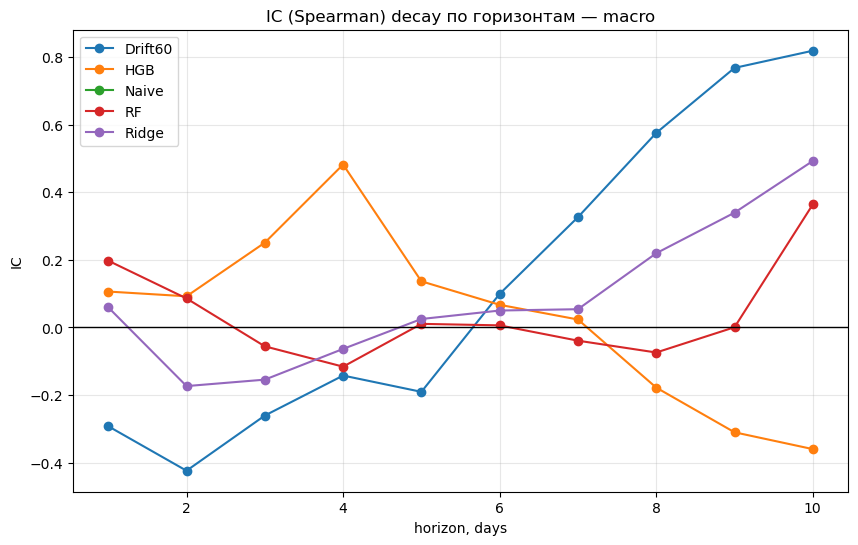


GRID SEARCH по правилам торговли


Grid search:   0%|          | 0/675 [00:00<?, ?it/s]


Top-15 правил по Sharpe (holdout):
           config model  threshold           sizing vol_filter  total_ret_net_%  cagr_%  max_dd_%  sharpe  sortino  win_rate_%  n_trades  exposure_%  turnover
macro_onchain_etf    RF        2.0           linear       none            0.031   0.370    -0.020   1.941      0.0       100.0         1       3.226     0.264
macro_onchain_etf    RF        2.0           linear    vol_q80            0.031   0.370    -0.020   1.941      0.0       100.0         1       3.226     0.264
macro_onchain_etf    RF        2.0           linear    vol_q60            0.031   0.370    -0.020   1.941      0.0       100.0         1       3.226     0.264
macro_onchain_etf    RF        2.0           binary       none            0.237   2.829    -0.150   1.941      0.0       100.0         1       3.226     2.000
macro_onchain_etf    RF        2.0           binary    vol_q80            0.237   2.829    -0.150   1.941      0.0       100.0         1       3.226     2.000
macro_onch

Grid OOF:   0%|          | 0/225 [00:00<?, ?it/s]


Top-15 правил по Sharpe (OOF):
  model  threshold           sizing vol_filter  total_ret_net_%  cagr_%  max_dd_%  sharpe  sortino  win_rate_%  n_trades  exposure_%  turnover
  Ridge        5.0           linear    vol_q80           13.699   6.924   -10.206   0.774    0.539      36.842        19      13.857    20.306
Drift60        1.0           binary    vol_q60           21.232  10.561   -22.996   0.612    0.553     100.000         1      32.000     7.000
Drift60        1.0           linear    vol_q60           21.232  10.561   -22.996   0.612    0.553     100.000         1      32.000     7.000
Drift60        1.0 threshold_linear    vol_q60           21.232  10.561   -22.996   0.612    0.553     100.000         1      32.000     7.000
Drift60        2.0           binary    vol_q60           21.232  10.561   -22.996   0.612    0.553     100.000         1      32.000     7.000
Drift60        2.0           linear    vol_q60           21.232  10.561   -22.996   0.612    0.553     100.000

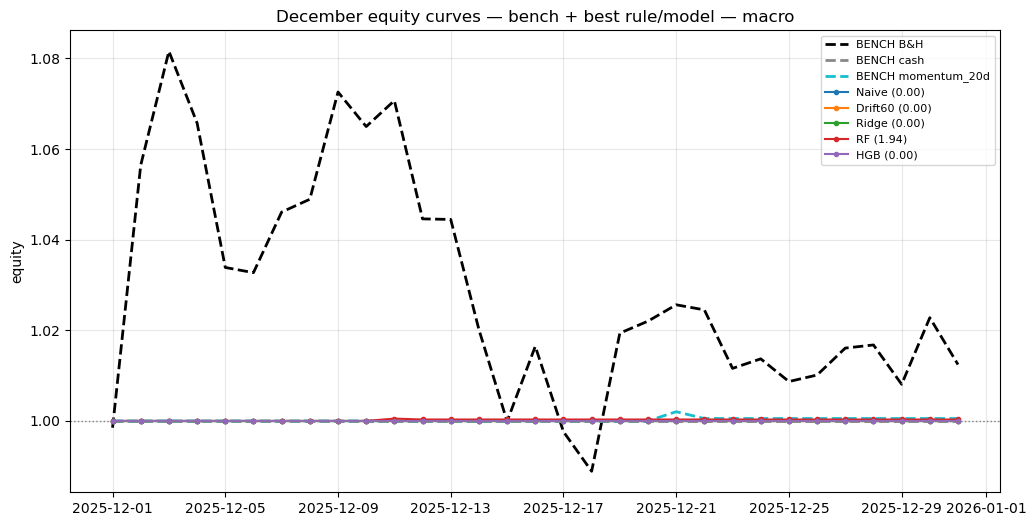

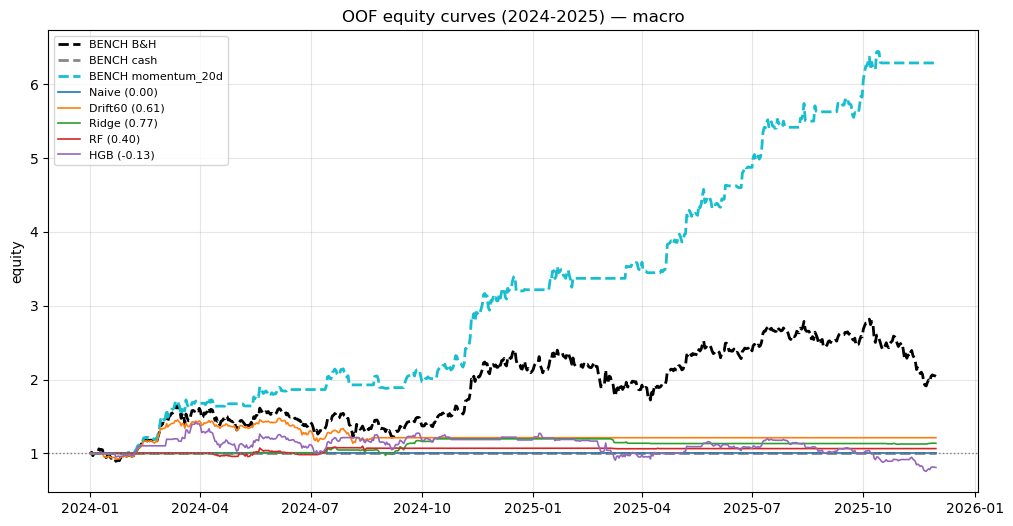

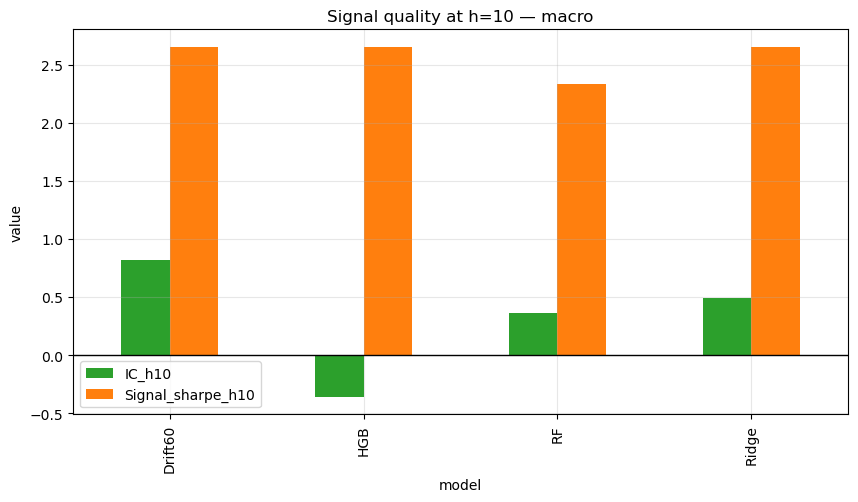


Saved v5.5 CSVs.

ИТОГИ
Best config: macro
Buy & Hold holdout: 1.24%, sharpe=0.589
Best rule on holdout (top-1): RF macro_onchain_etf, return=0.03%, sharpe=1.941

Compare to B&H OOF (104.24%):
Best OOF rule: Ridge, return=13.70%, sharpe=0.774


In [4]:
"""
================================================================
BTC 10-day forecast pipeline v5.5
================================================================
Отличия от v5.4:
  [A] Честные бенчмарки: B&H, cash, momentum_20d
  [B] Grid search по правилам торговли:
      threshold × position_sizing × vol_filter
  [C] Метрики качества сигнала:
      IC (Spearman), Hit rate по threshold, Signal Sharpe, Decay
  [D] Trade log для лучшей конфигурации
================================================================
"""

import os, warnings, itertools
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from scipy.stats import spearmanr

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from statsmodels.tsa.stattools import grangercausalitytests

# ============================================================
# 0. Конфиг
# ============================================================
CSV            = "crypto_daily_2022_2025_clean.csv"
EXOG_CACHE     = "exog_cache.csv"
CUTOFF         = pd.Timestamp("2025-11-30")
HOLDOUT_START  = pd.Timestamp("2025-12-01")
HOLDOUT_END    = pd.Timestamp("2025-12-31")
HORIZONS       = list(range(1, 11))
VAL_START      = pd.Timestamp("2024-01-01")
OOF_SPLITS     = 5

CALIB_LOOKBACK_DAYS = 90
CALIB_MIN_N         = 25
MIN_BIAS_TSTAT      = 2.0
EXCLUDE_BIAS_CORR   = {"Naive"}
CLIP_K              = 2.0
USE_VOL_SCALING     = True
VOL_NORMALIZE_RESID = True

RF_TREES     = 100
HGB_ITER     = 100
RIDGE_ALPHA  = 1.0
DRIFT_WINDOW = 60

GRANGER_MAXLAG = 10
GRANGER_PVALUE = 0.10

FRED_API_KEY    = None
CRYPTOQUANT_KEY = None

# --- backtest ---
BT_FEE_BPS  = 10
BT_SLIP_BPS = 5

# [B] grid search
GRID_THRESHOLDS = [0.0, 0.5, 1.0, 2.0, 5.0]
GRID_SIZINGS    = ["binary", "linear", "threshold_linear"]
GRID_VOL_FILTERS = ["none", "vol_q80", "vol_q60"]

# --- plot/export ---
SAVE_FIGS = True
FIG_DIR   = "figs"
np.random.seed(42)
if SAVE_FIGS: os.makedirs(FIG_DIR, exist_ok=True)

# ============================================================
# 1. Данные + экзогеника
# ============================================================
df_base = (pd.read_csv(CSV, parse_dates=["date"])
             .sort_values("date").reset_index(drop=True).ffill())
print(f"Base CSV: {df_base['date'].min().date()} … {df_base['date'].max().date()} "
      f"({len(df_base)} rows)")

def fetch_yfinance(tickers, start="2021-01-01", end="2026-01-01"):
    try:
        import yfinance as yf
    except ImportError:
        raise ImportError("pip install yfinance")
    out = {}
    for name, tk in tickers.items():
        try:
            h = yf.Ticker(tk).history(start=start, end=end, auto_adjust=True)
            if len(h) > 100 and "Close" in h.columns:
                s = h["Close"].rename(name)
                s.index = pd.to_datetime(s.index).tz_localize(None)
                out[name] = s
        except Exception:
            pass
    return pd.DataFrame(out).sort_index() if out else pd.DataFrame()

def fetch_trends(keyword="Bitcoin"):
    from pytrends.request import TrendReq
    p = TrendReq(hl="en-US", tz=0)
    p.build_payload([keyword], timeframe="2021-01-01 2025-12-31")
    t = p.interest_over_time().drop(columns=["isPartial"], errors="ignore")
    t.index = pd.to_datetime(t.index).tz_localize(None)
    return t

def collect_exog():
    ext = {}
    print("\nCollecting exog:")
    try:
        yf_data = fetch_yfinance({
            "dxy": "DX-Y.NYB", "t10y": "^TNX", "vix": "^VIX",
            "spx": "^GSPC", "gold": "GC=F", "oil": "CL=F",
        })
        print(f"  yfinance: {yf_data.shape}")
        for c in yf_data.columns: ext[c] = yf_data[c]
    except Exception as e:
        print(f"  yfinance: skip ({e})")
    try:
        tr = fetch_trends()
        print(f"  trends: {tr.shape}")
        ext["gtrends"] = tr.iloc[:, 0].rename("gtrends")
    except Exception as e:
        print(f"  trends: skip ({e})")
    if not ext: return pd.DataFrame()
    exog = pd.DataFrame(ext).sort_index()
    exog.index = pd.to_datetime(exog.index).tz_localize(None)
    return exog

if os.path.exists(EXOG_CACHE):
    print(f"\nLoading exog cache: {EXOG_CACHE}")
    exog = pd.read_csv(EXOG_CACHE, parse_dates=["date"]).set_index("date").sort_index()
    print(f"  loaded: {exog.shape}")
else:
    exog = collect_exog()
    if not exog.empty:
        exog.reset_index().rename(columns={"index": "date"}).to_csv(EXOG_CACHE, index=False)
        print(f"Saved: {EXOG_CACHE}")

if not exog.empty:
    exog = exog.resample("D").last().ffill().shift(1)

full = df_base.set_index("date").join(exog, how="left").reset_index()
print(f"Full: {full.shape}")

# ============================================================
# 2. Features
# ============================================================
def enrich_existing_macro(d):
    for c in ["dollar_index", "fed_funds_rate", "treasury_10y"]:
        if c not in d.columns: continue
        d[f"{c}_chg1"]       = d[c].diff(1)
        d[f"{c}_chg7"]       = d[c].diff(7)
        d[f"{c}_ma20_ratio"] = d[c] / d[c].rolling(20).mean() - 1
    d["fear_greed_ma20_ratio"] = d["fear_greed"] / d["fear_greed"].rolling(20).mean() - 1
    return d

def transform_exog_col(d, c):
    if c not in d.columns: return
    s = d[c]
    if c in ("m2", "etf_aum", "gtrends", "netflow"):
        d[f"{c}_log"] = np.log1p(s.clip(lower=0))
    d[f"{c}_ret"] = s.pct_change().replace([np.inf, -np.inf], np.nan)
    d[f"{c}_ma20_ratio"] = s / s.rolling(20).mean() - 1
    for lag in [1, 3, 7, 14]:
        d[f"{c}_lag{lag}"] = s.shift(lag)

def add_features(d):
    d = d.copy()
    d["btc_ret"] = np.log(d["BTC"]).diff()
    d["eth_ret"] = np.log(d["ETH"]).diff()
    d["sol_ret"] = np.log(d["SOL"]).diff()
    for lag in [1, 2, 3, 5, 10, 20]:
        d[f"btc_ret_lag{lag}"] = d["btc_ret"].shift(lag)
    d["vol5"]  = d["btc_ret"].rolling(5).std()
    d["vol20"] = d["btc_ret"].rolling(20).std()
    d["vol60"] = d["btc_ret"].rolling(60).std()
    d["vol_ratio_5_20"]  = d["vol5"]  / d["vol20"]
    d["vol_ratio_20_60"] = d["vol20"] / d["vol60"]
    d["vol_q60"]         = d["vol20"].rolling(60).rank(pct=True)
    d["ma20"] = d["BTC"].rolling(20).mean()
    d["ma50"] = d["BTC"].rolling(50).mean()
    d["dist_ma20"] = (d["BTC"] - d["ma20"]) / d["ma20"]
    d["dist_ma50"] = (d["BTC"] - d["ma50"]) / d["ma50"]
    d["hl_range"] = (d["BTC"].rolling(5).max() - d["BTC"].rolling(5).min()) / d["BTC"]
    d["fgi_chg1"] = d["fear_greed"].diff(1)
    d["fgi_chg7"] = d["fear_greed"].diff(7)
    # [A] momentum benchmark feature
    d["mom20d"] = d["BTC"].pct_change(20)
    d = enrich_existing_macro(d)
    for c in ["dxy","t10y","vix","spx","gold","oil","m2","tips10","fedfunds",
              "sopr","netflow","mvrv","etf_netflow","etf_aum","gtrends"]:
        if c in d.columns: transform_exog_col(d, c)
    return d

full = add_features(full)
for h in HORIZONS:
    full[f"y{h}"] = np.log(full["BTC"].shift(-h)) - np.log(full["BTC"])
print(f"Features: {full.shape}")

# ============================================================
# 3. Granger
# ============================================================
print("\nGranger test:")
granger_candidates = []
for c in ["dxy","t10y","vix","spx","gold","oil","m2","tips10","fedfunds",
          "sopr","netflow","mvrv","etf_netflow","etf_aum","gtrends"]:
    for suff in ["_ret","_ma20_ratio","_chg1","_chg7"]:
        col = f"{c}{suff}"
        if col in full.columns: granger_candidates.append(col)
for c in ["dollar_index","fed_funds_rate","treasury_10y","fear_greed"]:
    for suff in ["_chg1","_chg7","_ma20_ratio"]:
        col = f"{c}{suff}"
        if col in full.columns: granger_candidates.append(col)
granger_candidates = sorted(set(granger_candidates))

granger_significant = set()
for c in tqdm(granger_candidates, desc="Granger"):
    try:
        sub = pd.concat([full[["btc_ret"]], full[[c]]], axis=1).dropna()
        if len(sub) < 200: continue
        res = grangercausalitytests(sub, maxlag=GRANGER_MAXLAG, verbose=False)
        pvals = [res[l][0]["ssr_ftest"][1] for l in res]
        if min(pvals) < GRANGER_PVALUE:
            granger_significant.add(c)
    except Exception:
        continue

print(f"Significant: {len(granger_significant)}")
for c in sorted(granger_significant): print(f"  - {c}")

# ============================================================
# 4. Конфиги
# ============================================================
BASE_FEATURES = [
    "btc_ret","eth_ret","sol_ret",
    "btc_ret_lag1","btc_ret_lag2","btc_ret_lag3",
    "btc_ret_lag5","btc_ret_lag10","btc_ret_lag20",
    "vol5","vol20","vol60",
    "vol_ratio_5_20","vol_ratio_20_60","vol_q60",
    "dist_ma20","dist_ma50","hl_range",
    "fear_greed","fed_funds_rate","treasury_10y","dollar_index",
]

def pick(feats, prefixes):
    return [c for c in feats if any(c.startswith(p) for p in prefixes)]

MACRO_PREFIXES = (
    "dollar_index_","fed_funds_rate_","treasury_10y_","fear_greed_","fgi_",
    "dxy","t10y","vix","spx","gold","oil","m2","tips10","fedfunds",
)
ONCHAIN_PREFIXES = ("sopr","netflow","mvrv","etf_netflow","etf_aum","gtrends")

MACRO_FEATURES       = sorted(set(pick(granger_significant, MACRO_PREFIXES)))
ONCHAIN_ETF_FEATURES = sorted(set(pick(granger_significant, ONCHAIN_PREFIXES)))

CONFIGS = {
    "baseline":          BASE_FEATURES,
    "macro":             BASE_FEATURES + [f for f in MACRO_FEATURES if f not in BASE_FEATURES],
    "macro_onchain_etf": BASE_FEATURES + [f for f in (MACRO_FEATURES + ONCHAIN_ETF_FEATURES)
                                          if f not in BASE_FEATURES],
}
for name, feats in CONFIGS.items():
    print(f"{name}: {len(feats)} features")

# ============================================================
# 5. Split + модели
# ============================================================
train   = full[full["date"] <= CUTOFF].reset_index(drop=True)
holdout = full[(full["date"] >= HOLDOUT_START) &
               (full["date"] <= HOLDOUT_END)].reset_index(drop=True)
origin_date  = train["date"].iloc[-1]
origin_price = float(train["BTC"].iloc[-1])
print(f"\nOrigin: {origin_date.date()}, BTC = {origin_price:,.2f}")

class NaiveModel:
    def get_params(self, deep=False): return {}
    def set_params(self, **k): return self
    def fit(self, X, y): return self
    def predict(self, X): return np.zeros(len(X))

class DriftModel:
    def __init__(self, window=DRIFT_WINDOW): self.window = window
    def get_params(self, deep=False): return {"window": self.window}
    def set_params(self, **k):
        for key, v in k.items(): setattr(self, key, v)
        return self
    def fit(self, X, y):
        y = np.asarray(y)
        self.drift_ = float(np.mean(y[-self.window:]))
        return self
    def predict(self, X): return np.full(len(X), self.drift_)

def make_models():
    return {
        "Naive":   NaiveModel(),
        "Drift60": DriftModel(DRIFT_WINDOW),
        "Ridge":   make_pipeline(StandardScaler(), Ridge(alpha=RIDGE_ALPHA)),
        "RF":      RandomForestRegressor(n_estimators=RF_TREES, min_samples_leaf=5,
                                         random_state=42, n_jobs=-1),
        "HGB":     HistGradientBoostingRegressor(max_iter=HGB_ITER, learning_rate=0.05,
                                                 random_state=42),
    }

# ============================================================
# 6. OOF + калибровка + rolling
# ============================================================
def run_oof(train_df, models, features, horizons, val_start, n_splits):
    rows = []
    tscv = TimeSeriesSplit(n_splits=n_splits)
    splits = list(tscv.split(train_df))
    for name, model in models.items():
        for h in horizons:
            for tr_pos, te_pos in splits:
                tr_end = te_pos[0] - h
                if tr_end <= 100: continue
                tr_pos_clean = tr_pos[tr_pos < tr_end]
                if len(tr_pos_clean) < 100: continue
                tr = train_df.iloc[tr_pos_clean].dropna(subset=[f"y{h}"] + features)
                if len(tr) < 100: continue
                te = train_df.iloc[te_pos]
                te = te[te["date"] >= val_start]
                if len(te) == 0: continue
                m = clone(model)
                m.fit(tr[features], tr[f"y{h}"].values)
                fm = te[features]
                mask = ~fm.isna().any(axis=1)
                if mask.sum() == 0: continue
                pred_log = m.predict(fm[mask])
                te_ok = te.loc[mask]
                rows.append(pd.DataFrame({
                    "model": name, "horizon_days": h,
                    "forecast_origin": te_ok["date"].values,
                    "target_date": te_ok["date"].values + pd.Timedelta(days=h),
                    "current_close": te_ok["BTC"].values,
                    "vol20_at_origin": te_ok["vol20"].values,
                    "vol5_at_origin":  te_ok["vol5"].values,
                    "predicted_log_ret_raw": pred_log,
                }))
    out = pd.concat(rows, ignore_index=True)
    price_map = dict(zip(train_df["date"], train_df["BTC"]))
    out["actual_close"] = out["target_date"].map(price_map)
    out = out.dropna(subset=["actual_close"]).reset_index(drop=True)
    out["actual_log_ret"] = np.log(out["actual_close"] / out["current_close"])
    return out

def _calib_stats(err_after, vol_arr, vol5_arr):
    sigma = float(np.std(err_after, ddof=1))
    q025, q975 = np.quantile(err_after, [0.025, 0.975])
    vol_safe = np.where(np.isfinite(vol_arr) & (vol_arr > 0), vol_arr, np.nan)
    err_norm = err_after / vol_safe
    err_norm = err_norm[np.isfinite(err_norm)]
    if len(err_norm) > 20:
        q025_n, q975_n = np.quantile(err_norm, [0.025, 0.975])
        ref_vol = float(np.nanmean(vol_safe))
    else:
        q025_n, q975_n, ref_vol = None, None, float(np.nanmean(vol_safe))
    vol5_safe = np.where(np.isfinite(vol5_arr) & (vol5_arr > 0), vol5_arr, np.nan)
    ref_vol5 = float(np.nanmean(vol5_safe)) if np.isfinite(vol5_safe).any() else ref_vol
    return sigma, q025, q975, q025_n, q975_n, ref_vol, ref_vol5

def fit_global_calibration(oof):
    calib = []
    for (m, h), g in oof.groupby(["model", "horizon_days"]):
        err = (g["actual_log_ret"] - g["predicted_log_ret_raw"]).values
        n = len(err)
        bias_raw = float(np.mean(err))
        se = float(np.std(err, ddof=1)) / np.sqrt(n) if n > 1 else 0.0
        tstat = bias_raw / se if se > 0 else 0.0
        bias_used = 0.0 if (m in EXCLUDE_BIAS_CORR or abs(tstat) < MIN_BIAS_TSTAT) else bias_raw
        pred_corr = g["predicted_log_ret_raw"].values + bias_used
        err_after = g["actual_log_ret"].values - pred_corr
        sigma, q025, q975, q025_n, q975_n, ref_vol, ref_vol5 = _calib_stats(
            err_after, g["vol20_at_origin"].values, g["vol5_at_origin"].values)
        calib.append({
            "model": m, "horizon_days": h,
            "bias_raw": bias_raw, "bias_tstat": tstat,
            "bias": bias_used, "sigma": sigma,
            "clip_lo": -CLIP_K*sigma, "clip_hi": CLIP_K*sigma,
            "q025": float(q025), "q975": float(q975),
            "q025_norm": q025_n, "q975_norm": q975_n,
            "ref_vol": ref_vol, "ref_vol5": ref_vol5, "n_oof": n,
        })
    return pd.DataFrame(calib)

def calibrate_at_origin(sub_oof, model, h, origin_dt, lookback_days, min_n, fb):
    g = sub_oof[(sub_oof["target_date"] < origin_dt) &
                (sub_oof["target_date"] >= origin_dt - pd.Timedelta(days=lookback_days))]
    if len(g) < min_n:
        return dict(bias=fb["bias"], sigma=fb["sigma"],
                    clip_lo=fb["clip_lo"], clip_hi=fb["clip_hi"],
                    q025=fb["q025"], q975=fb["q975"],
                    q025_norm=fb["q025_norm"], q975_norm=fb["q975_norm"],
                    ref_vol=fb["ref_vol"], ref_vol5=fb["ref_vol5"],
                    n_oof=len(g), source="global_fallback")
    err = (g["actual_log_ret"] - g["predicted_log_ret_raw"]).values
    n = len(err)
    bias_raw = float(np.mean(err))
    se = float(np.std(err, ddof=1)) / np.sqrt(n) if n > 1 else 0.0
    tstat = bias_raw / se if se > 0 else 0.0
    bias_used = 0.0 if (model in EXCLUDE_BIAS_CORR or abs(tstat) < MIN_BIAS_TSTAT) else bias_raw
    pred_corr = g["predicted_log_ret_raw"].values + bias_used
    err_after = g["actual_log_ret"].values - pred_corr
    sigma, q025, q975, q025_n, q975_n, ref_vol, ref_vol5 = _calib_stats(
        err_after, g["vol20_at_origin"].values, g["vol5_at_origin"].values)
    return dict(bias=bias_used, sigma=sigma,
                clip_lo=-CLIP_K*sigma, clip_hi=CLIP_K*sigma,
                q025=float(q025), q975=float(q975),
                q025_norm=q025_n, q975_norm=q975_n,
                ref_vol=ref_vol, ref_vol5=ref_vol5,
                n_oof=n, source="rolling")

def build_rolling_calibration(oof, origins, models_list, horizons,
                              lookback_days, min_n, global_calib):
    rows = []
    for name in models_list:
        for h in horizons:
            sub = oof[(oof["model"] == name) & (oof["horizon_days"] == h)]
            fb_df = global_calib[(global_calib["model"] == name) &
                                 (global_calib["horizon_days"] == h)]
            if len(fb_df) == 0: continue
            fb = fb_df.iloc[0]
            for od in origins:
                c = calibrate_at_origin(sub, name, h, od, lookback_days, min_n, fb)
                rows.append({"model": name, "horizon_days": h,
                             "forecast_origin": od, **c})
    return pd.DataFrame(rows)

def apply_calibration(fc, calib, use_vol_scaling, vol_normalize):
    merge_keys = ["model", "horizon_days"]
    if "forecast_origin" in calib.columns and "forecast_origin" in fc.columns:
        merge_keys.append("forecast_origin")
    cols = merge_keys + ["bias","sigma","clip_lo","clip_hi","q025","q975",
                         "q025_norm","q975_norm","ref_vol","ref_vol5"]
    if "n_oof" in calib.columns: cols.append("n_oof")
    if "source" in calib.columns: cols.append("source")
    fc = fc.merge(calib[cols], on=merge_keys, how="left", validate="many_to_one")
    pred_corr = fc["predicted_log_ret_raw"] + fc["bias"].fillna(0)
    fc["predicted_log_ret"] = np.clip(pred_corr,
                                      fc["clip_lo"].fillna(-CLIP_K*0.1),
                                      fc["clip_hi"].fillna(CLIP_K*0.1))
    fc["predicted_close"] = fc["current_close"] * np.exp(fc["predicted_log_ret"])
    if "vol20_at_origin" in fc.columns:
        ref = fc["ref_vol"].fillna(0.025).values
        cur = fc["vol20_at_origin"].values
        cur = np.where(np.isfinite(cur) & (cur > 0), cur, ref)
        vol_eff = np.clip(cur, 0.3 * ref, 3.0 * ref)
    else:
        ref = fc["ref_vol"].fillna(0.025).values
        vol_eff = ref
    if "vol5_at_origin" in fc.columns and "ref_vol5" in fc.columns:
        ref5 = fc["ref_vol5"].fillna(fc["ref_vol"]).fillna(0.02).values
        cur5 = fc["vol5_at_origin"].values
        cur5 = np.where(np.isfinite(cur5) & (cur5 > 0), cur5, ref5)
        vol5_ratio = np.clip(cur5 / ref5, 0.4, 1.5)
    else:
        vol5_ratio = np.ones(len(fc))
    if vol_normalize and fc["q025_norm"].notna().any():
        q_lo = fc["q025_norm"].fillna(fc["q025"]).values * vol_eff * vol5_ratio
        q_hi = fc["q975_norm"].fillna(fc["q975"]).values * vol_eff * vol5_ratio
        scale = vol_eff / ref * vol5_ratio
    elif use_vol_scaling:
        scale = np.clip(vol_eff / ref, 0.3, 3.0) * vol5_ratio
        q_lo = fc["q025"].values * scale
        q_hi = fc["q975"].values * scale
    else:
        scale = np.ones(len(fc))
        q_lo = fc["q025"].values
        q_hi = fc["q975"].values
    fc["vol_scale"]   = scale
    fc["vol5_ratio"]  = vol5_ratio
    fc["lower_95"]    = fc["current_close"] * np.exp(fc["predicted_log_ret"] + q_lo)
    fc["upper_95"]    = fc["current_close"] * np.exp(fc["predicted_log_ret"] + q_hi)
    fc["predicted_return_pct"] = (np.exp(fc["predicted_log_ret"]) - 1) * 100
    if "actual_close" in fc.columns and fc["actual_close"].notna().any():
        fc["actual_log_ret"]    = np.log(fc["actual_close"] / fc["current_close"])
        fc["actual_return_pct"] = (np.exp(fc["actual_log_ret"]) - 1) * 100
        fc["error_usd"]         = fc["predicted_close"] - fc["actual_close"]
        fc["error_pct"]         = fc["error_usd"] / fc["actual_close"] * 100
        fc["in_95"] = ((fc["actual_close"] >= fc["lower_95"]) &
                       (fc["actual_close"] <= fc["upper_95"]))
    return fc

def rolling_forecasts(models, features, horizons, full_df, holdout_df,
                      rolling_calib, use_vol_scaling, vol_normalize):
    holdout_dates = sorted(holdout_df["date"].unique())
    price_map = dict(zip(holdout_df["date"], holdout_df["BTC"]))
    full_map = {d: i for i, d in enumerate(full_df["date"])}
    max_date = holdout_df["date"].max()
    rows = []
    for name, base in models.items():
        for h in horizons:
            fitted, last_fit_at = None, None
            for origin_i, od in enumerate(holdout_dates):
                target = od + pd.Timedelta(days=h)
                if target > max_date: continue
                if fitted is None or (origin_i - last_fit_at >= 1):
                    cutoff_date = od - pd.Timedelta(days=h)
                    tr = full_df[full_df["date"] <= cutoff_date].dropna(
                        subset=[f"y{h}"] + features)
                    if len(tr) < 200: continue
                    fitted = clone(base)
                    fitted.fit(tr[features], tr[f"y{h}"].values)
                    last_fit_at = origin_i
                idx = full_map[od]
                cur = float(full_df.iloc[idx]["BTC"])
                v20 = float(full_df.iloc[idx]["vol20"]) if pd.notna(full_df.iloc[idx]["vol20"]) else np.nan
                v5  = float(full_df.iloc[idx]["vol5"])  if pd.notna(full_df.iloc[idx]["vol5"])  else np.nan
                fm = full_df.iloc[[idx]][features]
                if fm.isna().any().any(): continue
                pred_log = float(fitted.predict(fm)[0])
                rows.append({
                    "model": name, "horizon_days": h,
                    "forecast_origin": od, "target_date": target,
                    "current_close": cur,
                    "vol20_at_origin": v20, "vol5_at_origin": v5,
                    "predicted_log_ret_raw": pred_log,
                    "actual_close": price_map.get(target, np.nan),
                })
    out = pd.DataFrame(rows)
    return apply_calibration(out, rolling_calib, use_vol_scaling, vol_normalize)

# ============================================================
# 7. Метрики точности
# ============================================================
def overall_metrics(fc, horizons_subset=None, regime_label="all"):
    g_all = fc.dropna(subset=["actual_close"])
    if horizons_subset is not None:
        g_all = g_all[g_all["horizon_days"].isin(horizons_subset)]
    rows = []
    for m, g in g_all.groupby("model"):
        err = g["predicted_close"] - g["actual_close"]
        dir_acc = np.mean(np.sign(g["predicted_return_pct"]) ==
                          np.sign(g["actual_return_pct"])) * 100
        corr = np.corrcoef(g["predicted_return_pct"], g["actual_return_pct"])[0, 1] \
               if len(g) > 2 else np.nan
        rows.append({
            "model": m, "regime": regime_label, "n": len(g),
            "MAE_USD": np.mean(np.abs(err)),
            "RMSE_USD": np.sqrt(np.mean(err**2)),
            "MAPE_%": np.mean(np.abs(err / g["actual_close"])) * 100,
            "Bias_USD": np.mean(err),
            "Coverage_95_%": g["in_95"].mean() * 100,
            "Mean_width_%": np.mean((g["upper_95"] - g["lower_95"]) / g["current_close"]) * 100,
            "Dir_acc_%": dir_acc,
            "Return_corr": corr,
        })
    return pd.DataFrame(rows)

# ============================================================
# 8. [C] Signal quality metrics
# ============================================================
def signal_quality_metrics(fc, h_focus=10):
    """IC, hit rate по threshold, signal sharpe, decay."""
    rows = []
    for m, g in fc.dropna(subset=["actual_close"]).groupby("model"):
        sub = g[g["horizon_days"] == h_focus]
        if len(sub) < 20: continue
        pred = sub["predicted_return_pct"].values
        act  = sub["actual_return_pct"].values
        ic, _ = spearmanr(pred, act)

        # Signal Sharpe: средний знаковый доход от «ставки» пропорционально сигналу
        sr_ret = np.sign(pred) * act
        sig_sharpe = sr_ret.mean() / sr_ret.std() * np.sqrt(252/ h_focus) \
                     if sr_ret.std() > 0 else np.nan

        # Hit rate по threshold
        hit_rates = {}
        for thr in [0.0, 0.5, 1.0, 2.0, 5.0]:
            mask_long  = pred > thr
            mask_short = pred < -thr
            if mask_long.sum() + mask_short.sum() < 5:
                hit_rates[f"hit_{thr}"] = np.nan
                hit_rates[f"n_{thr}"]   = 0
                continue
            correct_long  = (act[mask_long]  > 0).sum()
            correct_short = (act[mask_short] < 0).sum()
            total = mask_long.sum() + mask_short.sum()
            hit_rates[f"hit_{thr}"] = (correct_long + correct_short) / total * 100
            hit_rates[f"n_{thr}"]   = total

        # Decay: corr при разных h (для этой модели и всей выборки горизонтов)
        decay = {}
        for h in HORIZONS:
            sub_h = g[g["horizon_days"] == h]
            if len(sub_h) > 20:
                c, _ = spearmanr(sub_h["predicted_return_pct"],
                                 sub_h["actual_return_pct"])
                decay[f"ic_h{h}"] = c

        rows.append({
            "model": m,
            "IC_h{}".format(h_focus): ic,
            "Signal_sharpe_h{}".format(h_focus): sig_sharpe,
            **hit_rates,
            **decay,
        })
    return pd.DataFrame(rows)

# ============================================================
# 9. [A] Benchmarks
# ============================================================
def build_benchmarks(prices_df):
    """B&H, cash, momentum_20d как позиции на каждый день."""
    p = prices_df.set_index("date")["BTC"].sort_index()
    btc_ret = p.pct_change().fillna(0)

    bh = pd.Series(1.0, index=p.index)
    cash = pd.Series(0.0, index=p.index)
    mom20 = (p.pct_change(20) > 0).astype(int).reindex(p.index).fillna(0)
    return {"B&H": bh, "cash": cash, "momentum_20d": mom20}

def position_from_signal(signals, prices_df, threshold, sizing, vol_filter):
    """Универсальный расчёт позиции по сигналу и правилам."""
    p = prices_df.set_index("date")["BTC"].sort_index()
    sig = signals.reindex(p.index).fillna(0)

    if sizing == "binary":
        pos = (sig > threshold).astype(float)
    elif sizing == "linear":
        # позиция пропорциональна |signal| в диапазоне [threshold, 2*threshold]
        z = np.clip((sig - threshold) / max(threshold, 0.5), 0, 1)
        pos = pd.Series(z, index=sig.index)
    elif sizing == "threshold_linear":
        # всё, что ниже threshold — 0; от threshold до 2*thr — 0.5; выше 2*thr — 1.0
        pos = pd.Series(0.0, index=sig.index)
        pos[sig > threshold] = 0.5
        pos[sig > 2 * threshold + 0.5] = 1.0
    else:
        pos = pd.Series(0.0, index=sig.index)

    # vol filter
    if vol_filter != "none" and "vol20" in prices_df.columns:
        v = prices_df.set_index("date")["vol20"].reindex(p.index)
        if vol_filter == "vol_q80":
            cap = v.quantile(0.8)
            pos = pos.where(v <= cap, pos * 0.5)
        elif vol_filter == "vol_q60":
            cap = v.quantile(0.6)
            pos = pos.where(v <= cap, pos * 0.5)

    return pos.fillna(0)

def backtest_positions(pos, prices_df, fee_bps=10, slip_bps=5):
    p = prices_df.set_index("date")["BTC"].sort_index()
    btc_ret = p.pct_change().fillna(0)
    pos = pos.reindex(p.index).fillna(0)
    gross = pos * btc_ret
    trades = pos.diff().abs().fillna(pos.iloc[0])
    cost = trades * (fee_bps + slip_bps) / 1e4
    net = gross - cost
    equity = (1 + net).cumprod()

    n = len(equity)
    if n == 0:
        return {}, None, None, None

    total_ret = equity.iloc[-1] - 1
    cagr = equity.iloc[-1] ** (365/n) - 1 if equity.iloc[-1] > 0 else -1
    dd   = (equity / equity.cummax() - 1).min()
    mu, sd = net.mean(), net.std()
    sharpe  = mu/sd * np.sqrt(365) if sd > 0 else 0
    down = net[net<0].std()
    sortino = mu/down * np.sqrt(365) if down > 0 else 0

    # win rate по «сделкам» = непрерывным периодам позиции > 0
    in_pos = (pos > 0).astype(int)
    trades_series = in_pos.diff().fillna(0)
    entries = (trades_series == 1).sum()
    # доход по сделке
    trade_rets = []
    current_ret = 1.0
    in_trade = False
    for i in range(len(net)):
        if in_pos.iloc[i] == 1:
            current_ret *= (1 + net.iloc[i])
            in_trade = True
        else:
            if in_trade:
                trade_rets.append(current_ret - 1)
                current_ret = 1.0
                in_trade = False
    if in_trade:
        trade_rets.append(current_ret - 1)
    trade_rets = np.array(trade_rets) if trade_rets else np.array([0])
    win_rate = (trade_rets > 0).mean() * 100 if len(trade_rets) > 0 else 0

    metrics = {
        "total_ret_net_%": total_ret * 100,
        "cagr_%":          cagr * 100,
        "max_dd_%":        dd * 100,
        "sharpe":          sharpe,
        "sortino":         sortino,
        "win_rate_%":      win_rate,
        "n_trades":        int(entries),
        "exposure_%":      (pos > 0).mean() * 100,
        "turnover":        float(trades.sum()),
    }
    return metrics, equity, pos, trade_rets

def benchmark_equity(pos_or_weight, prices_df, fee_bps=10, slip_bps=5):
    return backtest_positions(pos_or_weight, prices_df, fee_bps, slip_bps)

# ============================================================
# 10. Main loop
# ============================================================
results = {}
all_metrics = []
all_regime = []

for cfg_name, features in CONFIGS.items():
    print(f"\n{'='*60}\nCONFIG: {cfg_name}  ({len(features)} features)\n{'='*60}")
    models = make_models()
    oof = run_oof(train, models, features, HORIZONS, VAL_START, OOF_SPLITS)
    print(f"OOF rows: {len(oof)}")
    global_calib = fit_global_calibration(oof)
    oof = apply_calibration(oof, global_calib, use_vol_scaling=False,
                            vol_normalize=VOL_NORMALIZE_RESID)
    holdout_origins = sorted(holdout["date"].unique())
    all_origins = [origin_date] + list(holdout_origins)
    rolling_calib = build_rolling_calibration(
        oof, all_origins, list(models.keys()), HORIZONS,
        CALIB_LOOKBACK_DAYS, CALIB_MIN_N, global_calib)
    rolling = rolling_forecasts(models, features, HORIZONS, full, holdout,
                                rolling_calib, USE_VOL_SCALING, VOL_NORMALIZE_RESID)
    m = overall_metrics(rolling); m["config"] = cfg_name
    all_metrics.append(m)
    for label, hsub in [("h1-3", range(1,4)), ("h4-7", range(4,8)), ("h8-10", range(8,11))]:
        mr = overall_metrics(rolling, list(hsub), f"{label}_{cfg_name}")
        mr["config"] = cfg_name
        all_regime.append(mr)
    results[cfg_name] = {"oof": oof, "rolling": rolling, "global_calib": global_calib,
                         "rolling_calib": rolling_calib, "metrics": m}
    print(m.round(3).to_string(index=False))

summary = pd.concat(all_metrics, ignore_index=True)
regime_all = pd.concat(all_regime, ignore_index=True)

print("\n" + "="*60)
print("MAE by model × config:")
print(summary.pivot_table(index="model", columns="config", values="MAE_USD").round(1).to_string())
print("\nReturn_corr by model × config:")
print(summary.pivot_table(index="model", columns="config", values="Return_corr").round(3).to_string())
print("\nCoverage by model × config:")
print(summary.pivot_table(index="model", columns="config", values="Coverage_95_%").round(2).to_string())

# ============================================================
# 11. [A] Benchmarks on holdout and OOF
# ============================================================
print("\n" + "="*60)
print("BENCHMARKS")
print("="*60)

bench = build_benchmarks(holdout)
bench_metrics = {}
bench_equity_curves = {}
for name, pos in bench.items():
    m, eq, pos_, _ = backtest_positions(pos, holdout, BT_FEE_BPS, BT_SLIP_BPS)
    m["name"] = name
    bench_metrics[name] = m
    bench_equity_curves[name] = eq

bench_oof = build_benchmarks(train[train["date"] >= VAL_START])
bench_oof_metrics = {}
bench_oof_curves = {}
for name, pos in bench_oof.items():
    m, eq, pos_, _ = backtest_positions(pos, train[train["date"] >= VAL_START],
                                        BT_FEE_BPS, BT_SLIP_BPS)
    m["name"] = name
    bench_oof_metrics[name] = m
    bench_oof_curves[name] = eq

bench_df = pd.DataFrame(bench_metrics).T
bench_oof_df = pd.DataFrame(bench_oof_metrics).T
print("\nHoldout benchmarks:")
print(bench_df.round(2).to_string())
print("\nOOF benchmarks:")
print(bench_oof_df.round(2).to_string())

# ============================================================
# 12. [C] Signal quality metrics per model
# ============================================================
best_cfg_h810 = regime_all[regime_all["regime"].str.contains("h8-10")] \
    .groupby("config")["MAE_USD"].mean().sort_values()
best_cfg = best_cfg_h810.index[0]
print(f"\nBest config (h8-10 MAE): {best_cfg}")

print("\n" + "="*60)
print(f"SIGNAL QUALITY METRICS (config={best_cfg})")
print("="*60)
sq = signal_quality_metrics(results[best_cfg]["rolling"], h_focus=10)
print(sq.round(3).to_string(index=False))

# Decay curves
fig, ax = plt.subplots(figsize=(10, 6))
for _, row in sq.iterrows():
    decay_vals = [row.get(f"ic_h{h}", np.nan) for h in HORIZONS]
    ax.plot(HORIZONS, decay_vals, marker="o", label=row["model"])
ax.axhline(0, color="black", lw=1)
ax.set_title(f"IC (Spearman) decay по горизонтам — {best_cfg}")
ax.set_xlabel("horizon, days"); ax.set_ylabel("IC")
ax.grid(alpha=0.3); ax.legend()
if SAVE_FIGS: fig.savefig(f"{FIG_DIR}/40_ic_decay_v55.png", dpi=130, bbox_inches="tight")
plt.show()

# ============================================================
# 13. [B] Grid search
# ============================================================
print("\n" + "="*60)
print("GRID SEARCH по правилам торговли")
print("="*60)

def signals_from_rolling(rolling_df, model_name, horizon=10):
    sub = rolling_df[(rolling_df["model"] == model_name) &
                     (rolling_df["horizon_days"] == horizon)]
    return sub.set_index("target_date")["predicted_return_pct"].sort_index()

grid_results = []
total = len(CONFIGS) * 5 * len(GRID_THRESHOLDS) * len(GRID_SIZINGS) * len(GRID_VOL_FILTERS)
pbar = tqdm(total=total, desc="Grid search")

for cfg_name in CONFIGS.keys():
    rolling_df = results[cfg_name]["rolling"]
    for model_name in ["Naive", "Drift60", "Ridge", "RF", "HGB"]:
        sig = signals_from_rolling(rolling_df, model_name, horizon=10)
        if len(sig) == 0: 
            pbar.update(len(GRID_THRESHOLDS) * len(GRID_SIZINGS) * len(GRID_VOL_FILTERS)); continue
        for thr, sz, vf in itertools.product(GRID_THRESHOLDS, GRID_SIZINGS, GRID_VOL_FILTERS):
            pos = position_from_signal(sig, holdout, thr, sz, vf)
            metrics, eq, pos_, _ = backtest_positions(pos, holdout,
                                                      BT_FEE_BPS, BT_SLIP_BPS)
            if not metrics: 
                pbar.update(1); continue
            row = {"config": cfg_name, "model": model_name,
                   "threshold": thr, "sizing": sz, "vol_filter": vf,
                   **metrics}
            grid_results.append(row)
            pbar.update(1)
pbar.close()

grid_df = pd.DataFrame(grid_results)
# Сортируем по sharpe — это главная метрика для сравнения стратегий
grid_df_sorted = grid_df.sort_values("sharpe", ascending=False).reset_index(drop=True)

print("\nTop-15 правил по Sharpe (holdout):")
print(grid_df_sorted.head(15).round(3).to_string(index=False))

# Лучшее правило
if len(grid_df_sorted) > 0:
    best_rule = grid_df_sorted.iloc[0]
    print(f"\nBest rule: config={best_rule['config']}, model={best_rule['model']}, "
          f"thr={best_rule['threshold']}, sizing={best_rule['sizing']}, "
          f"vol_filter={best_rule['vol_filter']}")
    print(f"  return={best_rule['total_ret_net_%']:.2f}%, "
          f"sharpe={best_rule['sharpe']:.3f}, dd={best_rule['max_dd_%']:.2f}%")

    # [D] Trade log для лучшего правила
    print("\n" + "="*60)
    print("TRADE LOG (best rule, December)")
    print("="*60)
    best_cfg_name = best_rule["config"]
    best_model    = best_rule["model"]
    sig = signals_from_rolling(results[best_cfg_name]["rolling"], best_model, 10)
    pos = position_from_signal(sig, holdout, best_rule["threshold"],
                               best_rule["sizing"], best_rule["vol_filter"])
    p_ = holdout.set_index("date")["BTC"].sort_index()
    btc_ret = p_.pct_change().fillna(0)
    trade_rows = []
    prev_pos = 0.0
    for d in pos.index:
        if d not in p_.index: continue
        cur_pos = float(pos.loc[d])
        chg = cur_pos - prev_pos
        if abs(chg) > 1e-9:
            trade_rows.append({
                "date": d.date(), "action": "BUY" if chg > 0 else "SELL",
                "delta": chg, "new_pos": cur_pos,
                "price": float(p_.loc[d]),
                "signal": float(sig.get(d, np.nan)) if d in sig.index else np.nan,
            })
        prev_pos = cur_pos
    trade_log = pd.DataFrame(trade_rows)
    if len(trade_log) > 0:
        print(trade_log.to_string(index=False))
    else:
        print("(no trades — all cash)")

# ============================================================
# 14. OOF grid search (для проверки на большем периоде)
# ============================================================
print("\n" + "="*60)
print("GRID SEARCH на OOF (2024-2025)")
print("="*60)

def signals_from_oof(oof_df, model_name, horizon=10):
    sub = oof_df[(oof_df["model"] == model_name) &
                 (oof_df["horizon_days"] == horizon)]
    return sub.set_index("target_date")["predicted_return_pct"].sort_index()

oof_prices = train[train["date"] >= VAL_START].copy()
grid_oof_results = []
total = 5 * len(GRID_THRESHOLDS) * len(GRID_SIZINGS) * len(GRID_VOL_FILTERS)
pbar = tqdm(total=total, desc="Grid OOF")

for model_name in ["Naive","Drift60","Ridge","RF","HGB"]:
    sig = signals_from_oof(results[best_cfg]["oof"], model_name, 10)
    if len(sig) == 0:
        pbar.update(len(GRID_THRESHOLDS) * len(GRID_SIZINGS) * len(GRID_VOL_FILTERS)); continue
    for thr, sz, vf in itertools.product(GRID_THRESHOLDS, GRID_SIZINGS, GRID_VOL_FILTERS):
        pos = position_from_signal(sig, oof_prices, thr, sz, vf)
        metrics, eq, pos_, _ = backtest_positions(pos, oof_prices, BT_FEE_BPS, BT_SLIP_BPS)
        if not metrics: pbar.update(1); continue
        grid_oof_results.append({"model": model_name, "threshold": thr,
                                 "sizing": sz, "vol_filter": vf, **metrics})
        pbar.update(1)
pbar.close()

grid_oof_df = pd.DataFrame(grid_oof_results)
grid_oof_sorted = grid_oof_df.sort_values("sharpe", ascending=False).reset_index(drop=True)
print("\nTop-15 правил по Sharpe (OOF):")
print(grid_oof_sorted.head(15).round(3).to_string(index=False))
print(f"\nBuy & Hold OOF: return={bench_oof_df.loc['B&H','total_ret_net_%']:.2f}%, "
      f"sharpe={bench_oof_df.loc['B&H','sharpe']:.3f}, "
      f"dd={bench_oof_df.loc['B&H','max_dd_%']:.2f}%")

# ============================================================
# 15. Plots
# ============================================================
colors = {"Naive":"#1f77b4","Drift60":"#ff7f0e","Ridge":"#2ca02c",
          "RF":"#d62728","HGB":"#9467bd",
          "B&H":"#000000","cash":"#888888","momentum_20d":"#17becf"}

# 15.1 Equity curves — benchmarks + models (holdout, best rule each)
fig, ax = plt.subplots(figsize=(12, 6))
for name, eq in bench_equity_curves.items():
    if eq is None: continue
    ax.plot(eq.index, eq.values, lw=2, ls="--", label=f"BENCH {name}",
            color=colors.get(name, "grey"))
# каждый model с лучшим правилом для этого model
for model_name in ["Naive","Drift60","Ridge","RF","HGB"]:
    sub = grid_df[grid_df["model"] == model_name].sort_values("sharpe", ascending=False)
    if len(sub) == 0: continue
    row = sub.iloc[0]
    sig = signals_from_rolling(results[row["config"]]["rolling"], model_name, 10)
    pos = position_from_signal(sig, holdout, row["threshold"], row["sizing"], row["vol_filter"])
    _, eq, _, _ = backtest_positions(pos, holdout, BT_FEE_BPS, BT_SLIP_BPS)
    if eq is None: continue
    ax.plot(eq.index, eq.values, lw=1.5, marker="o", ms=3,
            label=f"{model_name} ({row['sharpe']:.2f})",
            color=colors.get(model_name, "grey"))
ax.axhline(1.0, color="grey", ls=":", lw=1)
ax.set_title(f"December equity curves — bench + best rule/model — {best_cfg}")
ax.set_ylabel("equity"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
if SAVE_FIGS: fig.savefig(f"{FIG_DIR}/41_equity_holdout_v55.png", dpi=130, bbox_inches="tight")
plt.show()

# 15.2 OOF equity curves
fig, ax = plt.subplots(figsize=(12, 6))
for name, eq in bench_oof_curves.items():
    if eq is None: continue
    ax.plot(eq.index, eq.values, lw=2, ls="--", label=f"BENCH {name}",
            color=colors.get(name, "grey"))
for model_name in ["Naive","Drift60","Ridge","RF","HGB"]:
    sub = grid_oof_df[grid_oof_df["model"] == model_name].sort_values("sharpe", ascending=False)
    if len(sub) == 0: continue
    row = sub.iloc[0]
    sig = signals_from_oof(results[best_cfg]["oof"], model_name, 10)
    pos = position_from_signal(sig, oof_prices, row["threshold"], row["sizing"], row["vol_filter"])
    _, eq, _, _ = backtest_positions(pos, oof_prices, BT_FEE_BPS, BT_SLIP_BPS)
    if eq is None: continue
    ax.plot(eq.index, eq.values, lw=1.2,
            label=f"{model_name} ({row['sharpe']:.2f})",
            color=colors.get(model_name, "grey"))
ax.axhline(1.0, color="grey", ls=":", lw=1)
ax.set_title(f"OOF equity curves (2024-2025) — {best_cfg}")
ax.set_ylabel("equity"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
if SAVE_FIGS: fig.savefig(f"{FIG_DIR}/42_equity_oof_v55.png", dpi=130, bbox_inches="tight")
plt.show()

# 15.3 IC decay (уже построен выше)
# 15.4 Signal quality bar chart
fig, ax = plt.subplots(figsize=(10, 5))
sq_plot = sq.set_index("model")[["IC_h10", "Signal_sharpe_h10"]].dropna()
sq_plot.plot(kind="bar", ax=ax, color=["#2ca02c","#ff7f0e"])
ax.axhline(0, color="black", lw=1)
ax.set_title(f"Signal quality at h=10 — {best_cfg}")
ax.set_ylabel("value"); ax.grid(alpha=0.3)
if SAVE_FIGS: fig.savefig(f"{FIG_DIR}/43_signal_quality_v55.png", dpi=130, bbox_inches="tight")
plt.show()

# ============================================================
# 16. Export
# ============================================================
summary.to_csv("summary_v55.csv", index=False)
regime_all.to_csv("regime_v55.csv", index=False)
sq.to_csv("signal_quality_v55.csv", index=False)
bench_df.to_csv("bench_holdout_v55.csv")
bench_oof_df.to_csv("bench_oof_v55.csv")
grid_df_sorted.to_csv("grid_holdout_v55.csv", index=False)
grid_oof_sorted.to_csv("grid_oof_v55.csv", index=False)
if len(grid_df_sorted) > 0:
    grid_df_sorted.head(50).to_csv("top_rules_v55.csv", index=False)
if 'trade_log' in locals() and len(trade_log) > 0:
    trade_log.to_csv("trade_log_best_v55.csv", index=False)

for cfg, d in results.items():
    d["rolling"].to_csv(f"rolling_{cfg}_v55.csv", index=False)
print("\nSaved v5.5 CSVs.")

# Финальный вывод
print("\n" + "="*60)
print("ИТОГИ")
print("="*60)
print(f"Best config: {best_cfg}")
print(f"Buy & Hold holdout: {bench_df.loc['B&H','total_ret_net_%']:.2f}%, "
      f"sharpe={bench_df.loc['B&H','sharpe']:.3f}")
print(f"Best rule on holdout (top-1): {grid_df_sorted.iloc[0]['model']} "
      f"{grid_df_sorted.iloc[0]['config']}, "
      f"return={grid_df_sorted.iloc[0]['total_ret_net_%']:.2f}%, "
      f"sharpe={grid_df_sorted.iloc[0]['sharpe']:.3f}")
print(f"\nCompare to B&H OOF ({bench_oof_df.loc['B&H','total_ret_net_%']:.2f}%):")
print(f"Best OOF rule: {grid_oof_sorted.iloc[0]['model']}, "
      f"return={grid_oof_sorted.iloc[0]['total_ret_net_%']:.2f}%, "
      f"sharpe={grid_oof_sorted.iloc[0]['sharpe']:.3f}")

Проверка зависимостей
  [OK] torch 2.13.0+cu126, cuda=True
  [OK] xgboost 3.3.0
  [OK] statsmodels 0.14.5

Base CSV: 2022-01-01 … 2025-12-31 (1461 rows)
Exog loaded: (1831, 7), full=(1461, 15)
Features: 37 (base=21, macro=16)
Origin: 2025-11-30, BTC=90,382.00
Train: 1430, Holdout: 31

Модели зарегистрированы.

RUNNING OOF

--- ARIMAX walk-forward ---


ARIMAX:   0%|          | 0/140 [00:00<?, ?it/s]


--- QReg walk-forward ---

--- XGBoost walk-forward ---

--- LSTM walk-forward ---


LSTM:   0%|          | 0/70 [00:00<?, ?it/s]


--- TCN walk-forward ---


TCN:   0%|          | 0/70 [00:00<?, ?it/s]


--- Transformer walk-forward ---


Transformer:   0%|          | 0/70 [00:00<?, ?it/s]


OOF rows: 17380, models: ['ARIMAX', 'LSTM', 'QReg', 'TCN', 'Transformer', 'XGBoost']

OOF metrics per model:
      model    n  MAE_USD  RMSE_USD  MAPE_%  Bias_USD  Dir_acc_%  Return_corr
     ARIMAX 1393  3322.93   4476.19    4.12   -130.98      48.24        -0.04
       QReg 6945  3327.58   4513.12    4.14   -202.26      53.62         0.06
       LSTM  699  3628.26   4791.15    4.57    889.43      46.21         0.00
Transformer  699  3650.77   4806.39    4.58    815.15      47.93         0.01
        TCN  699  3774.57   5002.51    4.72   1008.52      46.92        -0.04
    XGBoost 6945  3852.05   5342.89    4.77    553.02      48.67        -0.07

ENSEMBLES
Base models: ['ARIMAX', 'LSTM', 'QReg', 'TCN', 'Transformer', 'XGBoost']

OOF weights (inverse MAE):
model
ARIMAX         0.180
LSTM           0.164
QReg           0.179
TCN            0.158
Transformer    0.163
XGBoost        0.155

OOF metrics WITH ensembles:
           model    n  MAE_USD  RMSE_USD  MAPE_%  Bias_USD  Dir_acc_%  

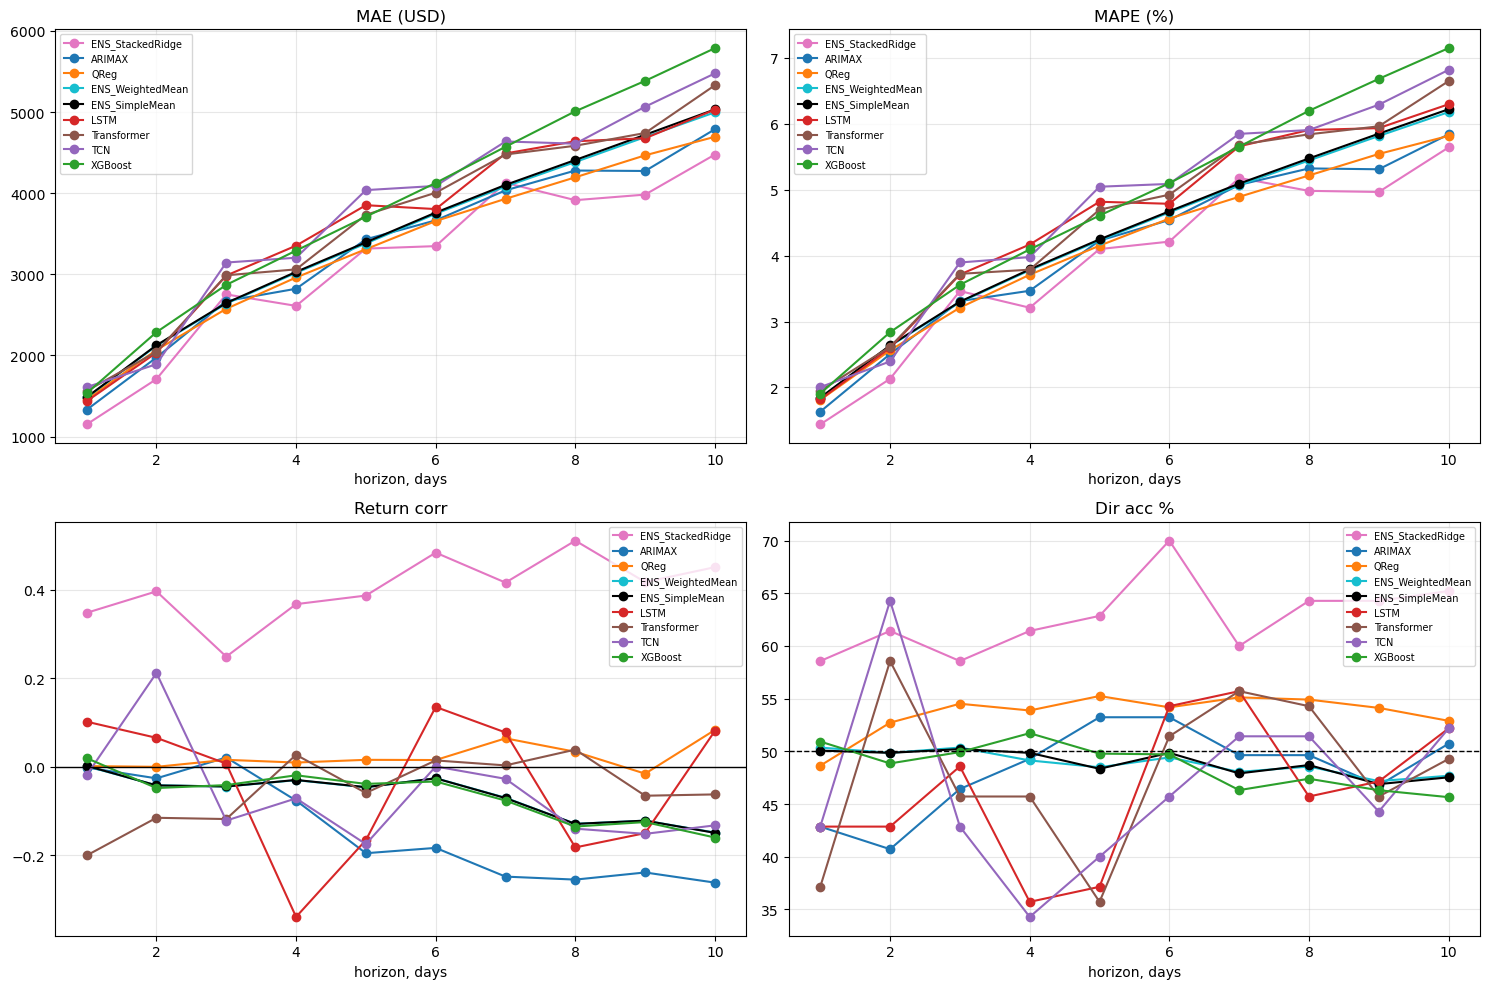

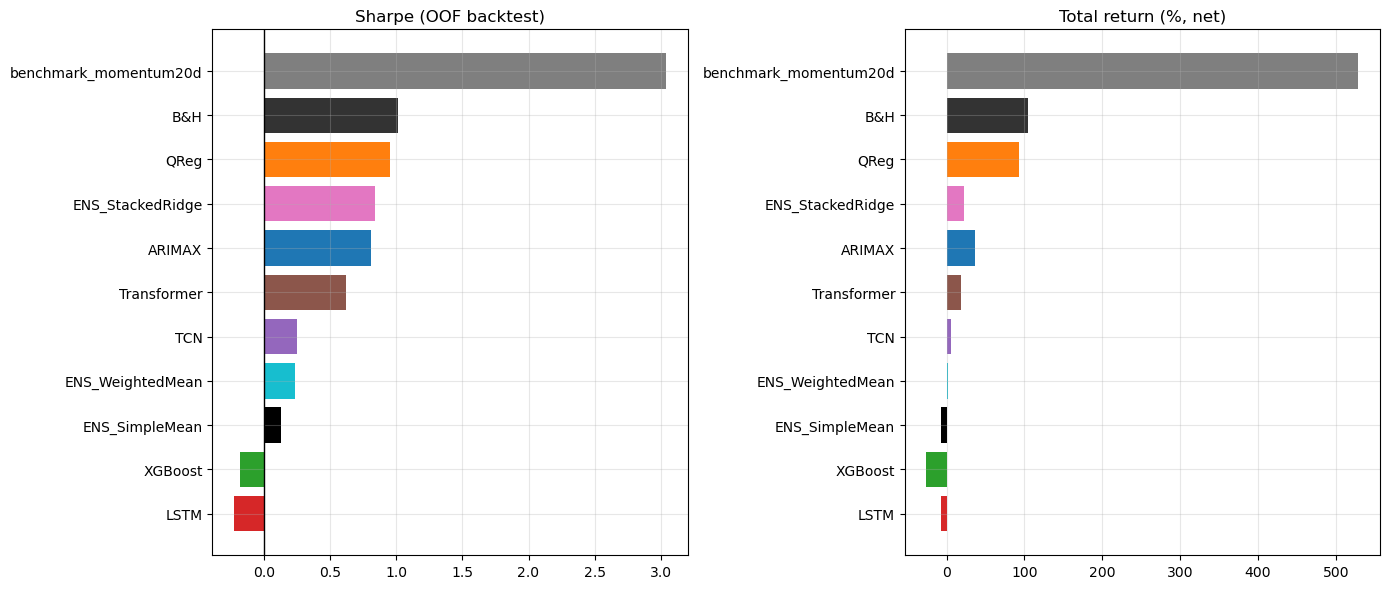


Saved v6 CSVs.

ИТОГИ v6
OOF MAE (все горизонты):
           model  MAE_USD  Return_corr  Dir_acc_%
ENS_StackedRidge  3136.97         0.44      62.66
          ARIMAX  3322.93        -0.04      48.24
            QReg  3327.58         0.06      53.62
ENS_WeightedMean  3449.63        -0.07      48.91
  ENS_SimpleMean  3466.25        -0.07      48.93
            LSTM  3628.26         0.00      46.21
     Transformer  3650.77         0.01      47.93
             TCN  3774.57        -0.04      46.92
         XGBoost  3852.05        -0.07      48.67

OOF h=8-10 MAE:
           model  MAE_USD  Return_corr  Dir_acc_%
ENS_StackedRidge  4122.75         0.46      64.59
          ARIMAX  4446.40        -0.25      49.04
            QReg  4452.34         0.02      53.98
ENS_WeightedMean  4690.69        -0.13      47.81
  ENS_SimpleMean  4720.29        -0.13      47.71
            LSTM  4781.42        -0.06      48.33
     Transformer  4883.54        -0.03      49.76
             TCN  5048.95       

In [7]:
"""
================================================================
BTC 10-day point forecast pipeline v6
================================================================
Модели:
  - ARIMAX           (statsmodels, классика)
  - QuantileRegressor (sklearn, медиана → точечный прогноз)
  - XGBoost          (или HGB как fallback)
  - LSTM             (PyTorch, multi-output)
  - TCN              (PyTorch, dilated causal convs, multi-output)
  - Transformer      (PyTorch, encoder-only, multi-output)

Ансамбли:
  - SimpleMean
  - WeightedMean (по обратному OOF-MAE)
  - StackedRidge (Ridge поверх OOF-прогнозов)

Оценка:
  - OOF 2024-2025 (walk-forward)
  - Rolling December holdout
  - MAE / RMSE / MAPE / Bias / Dir_acc / Return_corr
  - Backtest long/cash + benchmark momentum_20d

Если torch/xgboost нет — модели пропускаются, пайплайн продолжает.
================================================================
"""

import os, warnings, time, copy
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from sklearn.base import clone, BaseEstimator, RegressorMixin
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, QuantileRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.multioutput import MultiOutputRegressor

# ============================================================
# 0. Проверка зависимостей
# ============================================================
print("=" * 60)
print("Проверка зависимостей")
print("=" * 60)

HAVE_TORCH = False
HAVE_XGB   = False
HAVE_SM    = False   # statsmodels

try:
    import torch
    import torch.nn as nn
    import torch.optim as optim
    from torch.utils.data import DataLoader, TensorDataset
    HAVE_TORCH = True
    print(f"  [OK] torch {torch.__version__}, cuda={torch.cuda.is_available()}")
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
except ImportError:
    print("  [MISSING] torch — pip install torch")
    DEVICE = None

try:
    import xgboost as xgb
    HAVE_XGB = True
    print(f"  [OK] xgboost {xgb.__version__}")
except ImportError:
    print("  [MISSING] xgboost — pip install xgboost (fallback на HGB)")

try:
    import statsmodels.api as sm
    from statsmodels.tsa.arima.model import ARIMA
    HAVE_SM = True
    print(f"  [OK] statsmodels {sm.__version__}")
except ImportError:
    print("  [MISSING] statsmodels — pip install statsmodels")

# ============================================================
# 1. Config
# ============================================================
CSV            = "crypto_daily_2022_2025_clean.csv"
EXOG_CACHE     = "exog_cache.csv"
CUTOFF         = pd.Timestamp("2025-11-30")
HOLDOUT_START  = pd.Timestamp("2025-12-01")
HOLDOUT_END    = pd.Timestamp("2025-12-31")
HORIZONS       = list(range(1, 11))
VAL_START      = pd.Timestamp("2024-01-01")
OOF_SPLITS     = 5

# Neural nets
SEQ_LEN     = 30       # длина входной последовательности
HIDDEN      = 48
N_LAYERS    = 2
DROPOUT     = 0.2
LR          = 1e-3
WEIGHT_DECAY= 1e-4
EPOCHS      = 60
BATCH       = 64
PATIENCE    = 8        # early stopping
SEED        = 42

# Backtest
BT_FEE_BPS  = 10
BT_SLIP_BPS = 5
BT_THRESHOLD= 0.0

# Features config (как в v5.5)
USE_MACRO_EXOG = True   # добавление макро-признаков из exog_cache

SAVE_FIGS = True
FIG_DIR   = "figs_v6"
np.random.seed(SEED)
if HAVE_TORCH:
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
if SAVE_FIGS: os.makedirs(FIG_DIR, exist_ok=True)

# ============================================================
# 2. Данные и признаки
# ============================================================
df_base = (pd.read_csv(CSV, parse_dates=["date"])
             .sort_values("date").reset_index(drop=True).ffill())
print(f"\nBase CSV: {df_base['date'].min().date()} … {df_base['date'].max().date()} "
      f"({len(df_base)} rows)")

# --- exog (опционально, из кэша v5) ---
if USE_MACRO_EXOG and os.path.exists(EXOG_CACHE):
    exog = pd.read_csv(EXOG_CACHE, parse_dates=["date"]).set_index("date").sort_index()
    exog = exog.resample("D").last().ffill().shift(1)
    df = df_base.set_index("date").join(exog, how="left").reset_index()
    print(f"Exog loaded: {exog.shape}, full={df.shape}")
else:
    df = df_base.copy()
    exog = pd.DataFrame()
    print("Exog not used")

# --- features ---
def add_features(d):
    d = d.copy()
    d["btc_ret"] = np.log(d["BTC"]).diff()
    d["eth_ret"] = np.log(d["ETH"]).diff()
    d["sol_ret"] = np.log(d["SOL"]).diff()
    for lag in [1, 2, 3, 5, 10, 20]:
        d[f"btc_ret_lag{lag}"] = d["btc_ret"].shift(lag)
    d["vol5"]  = d["btc_ret"].rolling(5).std()
    d["vol20"] = d["btc_ret"].rolling(20).std()
    d["vol60"] = d["btc_ret"].rolling(60).std()
    d["vol_ratio_5_20"]  = d["vol5"] / d["vol20"]
    d["vol_ratio_20_60"] = d["vol20"] / d["vol60"]
    d["ma20"] = d["BTC"].rolling(20).mean()
    d["ma50"] = d["BTC"].rolling(50).mean()
    d["dist_ma20"] = (d["BTC"] - d["ma20"]) / d["ma20"]
    d["dist_ma50"] = (d["BTC"] - d["ma50"]) / d["ma50"]
    d["hl_range"] = (d["BTC"].rolling(5).max() - d["BTC"].rolling(5).min()) / d["BTC"]
    d["fgi_chg1"] = d["fear_greed"].diff(1)
    d["fgi_chg7"] = d["fear_greed"].diff(7)
    # макро-производные от базовых
    for c in ["dollar_index", "fed_funds_rate", "treasury_10y"]:
        if c in d.columns:
            d[f"{c}_chg1"] = d[c].diff(1)
            d[f"{c}_chg7"] = d[c].diff(7)
            d[f"{c}_ma20_ratio"] = d[c] / d[c].rolling(20).mean() - 1
    # экзогенные производные
    for c in ["dxy", "t10y", "vix", "spx", "gold", "oil", "gtrends"]:
        if c in d.columns:
            d[f"{c}_ret"] = d[c].pct_change().replace([np.inf, -np.inf], np.nan)
            d[f"{c}_ma20_ratio"] = d[c] / d[c].rolling(20).mean() - 1
    return d

df = add_features(df)

BASE_FEATURES = [
    "btc_ret", "eth_ret", "sol_ret",
    "btc_ret_lag1", "btc_ret_lag2", "btc_ret_lag3",
    "btc_ret_lag5", "btc_ret_lag10", "btc_ret_lag20",
    "vol5", "vol20", "vol60",
    "vol_ratio_5_20", "vol_ratio_20_60",
    "dist_ma20", "dist_ma50", "hl_range",
    "fear_greed", "fed_funds_rate", "treasury_10y", "dollar_index",
]

MACRO_EXOG = [
    c for c in [
        "dxy_ret", "dxy_ma20_ratio", "t10y_ret", "t10y_ma20_ratio",
        "vix_ret", "vix_ma20_ratio", "spx_ret", "spx_ma20_ratio",
        "gold_ret", "oil_ma20_ratio", "gtrends_ret",
        "dollar_index_chg7", "fed_funds_rate_chg7", "treasury_10y_chg7",
        "treasury_10y_ma20_ratio", "fed_funds_rate_ma20_ratio",
    ] if c in df.columns
]

FEATURES = BASE_FEATURES + (MACRO_EXOG if USE_MACRO_EXOG else [])

# targets (multi-output, log-return)
for h in HORIZONS:
    df[f"y{h}"] = np.log(df["BTC"].shift(-h)) - np.log(df["BTC"])

print(f"Features: {len(FEATURES)} (base={len(BASE_FEATURES)}, macro={len(MACRO_EXOG)})")

# ============================================================
# 3. Train / holdout split
# ============================================================
train   = df[df["date"] <= CUTOFF].reset_index(drop=True)
holdout = df[(df["date"] >= HOLDOUT_START) & (df["date"] <= HOLDOUT_END)].reset_index(drop=True)

origin_date  = train["date"].iloc[-1]
origin_price = float(train["BTC"].iloc[-1])
print(f"Origin: {origin_date.date()}, BTC={origin_price:,.2f}")
print(f"Train: {len(train)}, Holdout: {len(holdout)}")

# ============================================================
# 4. Общие утилиты
# ============================================================
def make_targets(d, h):
    """Для каждой строки — log-return на горизонте h."""
    return d[f"y{h}"].values

def eval_forecast(y_true, y_pred, label=""):
    err = y_pred - y_true
    return {
        "label": label,
        "n": len(err),
        "MAE": float(np.mean(np.abs(err))),
        "RMSE": float(np.sqrt(np.mean(err**2))),
        "Bias": float(np.mean(err)),
    }

# ============================================================
# 5. Классы моделей (sklearn-compatible)
# ============================================================
class ARIMAXModel(BaseEstimator, RegressorMixin):
    """ARIMA(p,0,q) на log-return, опционально с exog-регрессорами.
    Возвращает прогноз log-return на h шагов вперёд (не цену!)."""
    def __init__(self, order=(2, 0, 2), use_exog=True):
        self.order = order
        self.use_exog = use_exog

    def fit(self, X, y):
        # X: признаковая матрица (n, k), y: log-return
        # Используем упрощённый ARIMAX: ARIMA на y, exog — конкатенация последних k экзо-регрессоров
        # Для скорости — ARIMA без exog, если statsmodels недоступен или слишком медленно
        y = np.asarray(y, dtype=float)
        self.y_last_ = y[-1] if len(y) > 0 else 0.0
        self.use_exog_ = self.use_exog and HAVE_SM
        if HAVE_SM:
            try:
                # ARIMA без exog для скорости — горизонт прогноза всё равно > seq_len
                self.model_ = ARIMA(y, order=self.order).fit(method_kwargs={"warn_convergence": False})
            except Exception:
                self.model_ = None
        else:
            self.model_ = None
        return self

    def predict(self, X, horizon=1):
        if self.model_ is not None:
            try:
                fc = self.model_.forecast(steps=horizon)
                return np.asarray(fc)
            except Exception:
                pass
        # fallback: последнее значение
        return np.full(horizon, self.y_last_)


class QRegModel(BaseEstimator, RegressorMixin):
    """QuantileRegressor(q=0.5) — медиана как точечный прогноз."""
    def __init__(self, quantile=0.5, alpha=1.0):
        self.quantile = quantile
        self.alpha = alpha

    def fit(self, X, y):
        self.pipe_ = make_pipeline(
            StandardScaler(),
            QuantileRegressor(quantile=self.quantile, alpha=self.alpha,
                              solver="highs", fit_intercept=True)
        )
        self.pipe_.fit(X, y)
        return self

    def predict(self, X):
        return self.pipe_.predict(X)


class XGBModel(BaseEstimator, RegressorMixin):
    """XGBoost с fallback на HGB."""
    def __init__(self, n_estimators=200, max_depth=4, lr=0.05):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.lr = lr

    def fit(self, X, y):
        if HAVE_XGB:
            self.model_ = xgb.XGBRegressor(
                n_estimators=self.n_estimators, max_depth=self.max_depth,
                learning_rate=self.lr, subsample=0.8, colsample_bytree=0.8,
                reg_alpha=0.1, reg_lambda=1.0, random_state=SEED,
                n_jobs=-1, verbosity=0,
            )
        else:
            from sklearn.ensemble import HistGradientBoostingRegressor
            self.model_ = HistGradientBoostingRegressor(
                max_iter=self.n_estimators, learning_rate=self.lr,
                max_depth=self.max_depth, random_state=SEED,
            )
        self.model_.fit(X, y)
        return self

    def predict(self, X):
        return self.model_.predict(X)


# ============================================================
# 6. Sequence-based NN (LSTM / TCN / Transformer)
# ============================================================
if HAVE_TORCH:

    class SequenceDataset:
        """Готовит последовательности (n_samples, seq_len, n_features) → (n_samples, n_horizons)."""
        def __init__(self, df, feature_cols, horizon_cols, seq_len):
            self.seq_len = seq_len
            self.feature_cols = feature_cols
            self.horizon_cols = horizon_cols
            # отбрасываем строки с NaN в фичах или целях
            sub = df[feature_cols + horizon_cols].dropna()
            self.dates = df.loc[sub.index, "date"].values
            self.X_full = sub[feature_cols].values.astype(np.float32)
            self.y_full = sub[horizon_cols].values.astype(np.float32)
            self.index_map = {d: i for i, d in enumerate(df["date"])}

        def make_windows(self, idx_end, n_windows):
            """Возвращает X,y для последних n_windows последовательностей,
            заканчивающихся в позициях idx_end-n_windows ... idx_end-1.
            Здесь idx_end — позиция в self.X_full."""
            Xs, ys = [], []
            for e in range(n_windows):
                end = idx_end - e
                if end < self.seq_len:
                    continue
                Xs.append(self.X_full[end - self.seq_len:end])
                ys.append(self.y_full[end])
            if not Xs:
                return np.empty((0, self.seq_len, len(self.feature_cols))), np.empty((0, len(self.horizon_cols)))
            return np.stack(Xs), np.stack(ys)


    class LSTMNet(nn.Module):
        def __init__(self, n_feat, hidden=HIDDEN, n_layers=N_LAYERS, n_out=10, dropout=DROPOUT):
            super().__init__()
            self.lstm = nn.LSTM(n_feat, hidden, num_layers=n_layers,
                                batch_first=True, dropout=dropout if n_layers > 1 else 0.0)
            self.head = nn.Sequential(
                nn.LayerNorm(hidden),
                nn.Dropout(dropout),
                nn.Linear(hidden, n_out),
            )

        def forward(self, x):
            o, _ = self.lstm(x)
            return self.head(o[:, -1, :])


    class TCNBlock(nn.Module):
        def __init__(self, in_ch, out_ch, kernel_size, dilation, dropout):
            super().__init__()
            self.conv = nn.Conv1d(in_ch, out_ch, kernel_size,
                                  padding=(kernel_size - 1) * dilation,
                                  dilation=dilation)
            self.chomp = (kernel_size - 1) * dilation
            self.norm = nn.BatchNorm1d(out_ch)
            self.drop = nn.Dropout(dropout)
            self.act = nn.ReLU()
            self.down = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else None

        def forward(self, x):
            y = self.conv(x)
            if self.chomp > 0:
                y = y[:, :, :-self.chomp]  # causal trim
            y = self.act(self.norm(y))
            y = self.drop(y)
            res = x if self.down is None else self.down(x)
            return y + res


    class TCNNet(nn.Module):
        def __init__(self, n_feat, hidden=HIDDEN, n_out=10, dropout=DROPOUT):
            super().__init__()
            # вход: (B, seq_len, n_feat) → conv1d ждёт (B, n_feat, seq_len)
            self.blocks = nn.Sequential(
                TCNBlock(n_feat, hidden, 3, 1, dropout),
                TCNBlock(hidden, hidden, 3, 2, dropout),
                TCNBlock(hidden, hidden, 3, 4, dropout),
            )
            self.head = nn.Sequential(
                nn.LayerNorm(hidden),
                nn.Dropout(dropout),
                nn.Linear(hidden, n_out),
            )

        def forward(self, x):
            x = x.transpose(1, 2)   # (B, n_feat, seq_len)
            x = self.blocks(x)      # (B, hidden, seq_len)
            x = x[:, :, -1]         # последний таймстеп
            return self.head(x)


    class TransformerNet(nn.Module):
        def __init__(self, n_feat, hidden=HIDDEN, n_layers=N_LAYERS, n_heads=4,
                     n_out=10, dropout=DROPOUT, max_len=64):
            super().__init__()
            self.proj = nn.Linear(n_feat, hidden)
            self.pos  = nn.Parameter(torch.zeros(1, max_len, hidden))
            encoder_layer = nn.TransformerEncoderLayer(
                d_model=hidden, nhead=n_heads, dim_feedforward=hidden*2,
                dropout=dropout, batch_first=True, activation="gelu",
            )
            self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)
            self.head = nn.Sequential(
                nn.LayerNorm(hidden),
                nn.Dropout(dropout),
                nn.Linear(hidden, n_out),
            )

        def forward(self, x):
            B, T, _ = x.shape
            h = self.proj(x) + self.pos[:, :T, :]
            h = self.encoder(h)
            return self.head(h[:, -1, :])


    def train_nn(model, X_train, y_train, X_val, y_val, epochs=EPOCHS,
                 batch_size=BATCH, patience=PATIENCE, lr=LR, wd=WEIGHT_DECAY):
        """Обучает NN с early stopping по val loss."""
        model = model.to(DEVICE)
        opt = optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
        loss_fn = nn.MSELoss()

        Xt = torch.tensor(X_train, dtype=torch.float32)
        yt = torch.tensor(y_train, dtype=torch.float32)
        Xv = torch.tensor(X_val, dtype=torch.float32) if X_val is not None else None
        yv = torch.tensor(y_val, dtype=torch.float32) if y_val is not None else None

        ds = TensorDataset(Xt, yt)
        dl = DataLoader(ds, batch_size=batch_size, shuffle=True)

        best_val = np.inf
        best_state = None
        bad_epochs = 0

        for ep in range(epochs):
            model.train()
            for xb, yb in dl:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                opt.zero_grad()
                pred = model(xb)
                loss = loss_fn(pred, yb)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step()

            if Xv is not None:
                model.eval()
                with torch.no_grad():
                    pv = model(Xv.to(DEVICE)).cpu()
                    val_loss = loss_fn(pv, yv).item()
                if val_loss < best_val - 1e-6:
                    best_val = val_loss
                    best_state = copy.deepcopy(model.state_dict())
                    bad_epochs = 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= patience:
                        break

        if best_state is not None:
            model.load_state_dict(best_state)
        return model, best_val


    def nn_predict(model, X):
        model.eval()
        with torch.no_grad():
            pred = model(torch.tensor(X, dtype=torch.float32).to(DEVICE)).cpu().numpy()
        return pred

print("\nМодели зарегистрированы.")

# ============================================================
# 7. OOF walk-forward
# ============================================================
def run_oof_v6(df_train, features, horizons, val_start, n_splits):
    """
    Для каждой модели — OOF-прогнозы всех 10 горизонтов.
    Возвращает DataFrame с колонками: model, horizon, forecast_origin, target_date,
    current_close, predicted_log_ret, actual_close, actual_log_ret.
    """
    # Готовим y как multi-output матрицу
    y_cols = [f"y{h}" for h in horizons]
    valid_mask = df_train[features + y_cols].notna().all(axis=1)
    dfv = df_train[valid_mask].reset_index(drop=True)

    price_map = dict(zip(dfv["date"], dfv["BTC"]))

    rows = []

    # ==== ARIMA / ARIMAX: одна модель на origin, прогноз 1..10 ====
    if HAVE_SM:
        print("\n--- ARIMAX walk-forward ---")
        val_dates = dfv[dfv["date"] >= val_start]["date"].tolist()
        # шаг = 5 дней для скорости
        for d in tqdm(val_dates[::5], desc="ARIMAX"):
            idx = dfv.index[dfv["date"] == d][0]
            if idx < 100: continue
            hist = dfv.iloc[:idx]
            y_hist = hist["btc_ret"].dropna().values
            if len(y_hist) < 100: continue
            m = ARIMAXModel(order=(2, 0, 2), use_exog=False)
            m.fit(None, y_hist)
            fc = m.predict(None, horizon=10)
            cur_price = float(dfv.loc[idx, "BTC"])
            for h in horizons:
                target = d + pd.Timedelta(days=h)
                actual = price_map.get(target, np.nan)
                rows.append({
                    "model": "ARIMAX",
                    "horizon_days": h,
                    "forecast_origin": d,
                    "target_date": target,
                    "current_close": cur_price,
                    "predicted_log_ret": float(fc[h - 1]),
                    "actual_close": actual,
                })

    # ==== Sklearn-модели: QuantileRegressor + XGBoost (multi-output) ====
    from sklearn.multioutput import MultiOutputRegressor

    sklearn_models = {
        "QReg":     MultiOutputRegressor(QRegModel(quantile=0.5, alpha=1.0)),
        "XGBoost":  MultiOutputRegressor(XGBModel(n_estimators=150, max_depth=4, lr=0.05)),
    }

    for name, base in sklearn_models.items():
        print(f"\n--- {name} walk-forward ---")
        tscv = TimeSeriesSplit(n_splits=n_splits)
        splits = list(tscv.split(dfv))
        for tr_pos, te_pos in splits:
            te = dfv.iloc[te_pos]
            te = te[te["date"] >= val_start]
            if len(te) == 0: continue
            # purge
            te_min_pos = te_pos[0]
            tr_end = te_min_pos - 10  # purge 10 дней
            tr_pos_clean = tr_pos[tr_pos < tr_end]
            if len(tr_pos_clean) < 200: continue
            tr = dfv.iloc[tr_pos_clean].dropna(subset=features + y_cols)
            if len(tr) < 200: continue

            Xtr = tr[features].values
            Ytr = tr[y_cols].values

            m = clone(base)
            m.fit(Xtr, Ytr)

            te_ok = te.dropna(subset=features)
            if len(te_ok) == 0: continue
            Xte = te_ok[features].values
            Yte_pred = m.predict(Xte)

            for i, (_, row) in enumerate(te_ok.iterrows()):
                for j, h in enumerate(horizons):
                    target = row["date"] + pd.Timedelta(days=h)
                    rows.append({
                        "model": name,
                        "horizon_days": h,
                        "forecast_origin": row["date"],
                        "target_date": target,
                        "current_close": float(row["BTC"]),
                        "predicted_log_ret": float(Yte_pred[i, j]),
                        "actual_close": price_map.get(target, np.nan),
                    })

    # ==== NN: LSTM / TCN / Transformer ====
    if HAVE_TORCH:
        for model_cls, model_name in [(LSTMNet, "LSTM"),
                                      (TCNNet, "TCN"),
                                      (TransformerNet, "Transformer")]:
            print(f"\n--- {model_name} walk-forward ---")
            seq_ds = SequenceDataset(dfv, features, y_cols, seq_len=SEQ_LEN)

            val_idx = [i for i, d in enumerate(dfv["date"]) if d >= val_start]
            # шаг 10 дней для скорости
            val_idx_step = val_idx[::10]

            for pos in tqdm(val_idx_step, desc=model_name):
                if pos < SEQ_LEN + 100: continue
                # train: последние 800 дней до pos-10
                train_end = pos - 10
                train_start = max(SEQ_LEN, train_end - 800)
                Xtr, Ytr = seq_ds.make_windows(train_end, train_end - train_start - SEQ_LEN)
                if len(Xtr) < 100: continue

                # val: последние 80 дней до pos-10
                val_end = train_end
                val_start_idx = max(SEQ_LEN, val_end - 80)
                Xv, Yv = seq_ds.make_windows(val_end, val_end - val_start_idx - SEQ_LEN)

                try:
                    model = model_cls(n_feat=len(features), hidden=HIDDEN,
                                      n_out=len(horizons))
                    model, _ = train_nn(model, Xtr, Ytr,
                                        Xv if len(Xv) > 0 else None,
                                        Yv if len(Yv) > 0 else None,
                                        epochs=EPOCHS)
                except Exception as e:
                    continue

                # preidct для точки pos (origin)
                if pos < SEQ_LEN: continue
                X_pred = seq_ds.X_full[pos - SEQ_LEN:pos][None, ...]
                preds = nn_predict(model, X_pred)[0]
                cur = float(dfv.loc[pos, "BTC"])
                d = dfv.loc[pos, "date"]
                for j, h in enumerate(horizons):
                    target = d + pd.Timedelta(days=h)
                    rows.append({
                        "model": model_name,
                        "horizon_days": h,
                        "forecast_origin": d,
                        "target_date": target,
                        "current_close": cur,
                        "predicted_log_ret": float(preds[j]),
                        "actual_close": price_map.get(target, np.nan),
                    })

    out = pd.DataFrame(rows)
    out = out.dropna(subset=["actual_close"]).reset_index(drop=True)
    out["actual_log_ret"] = np.log(out["actual_close"] / out["current_close"])
    out["predicted_close"] = out["current_close"] * np.exp(out["predicted_log_ret"])
    return out

# ============================================================
# 8. Оценка
# ============================================================
def metrics_by_horizon(fc, by="model"):
    rows = []
    for (m, h), g in fc.groupby([by, "horizon_days"]):
        err = g["predicted_close"] - g["actual_close"]
        pred_ret = (np.exp(g["predicted_log_ret"]) - 1) * 100
        act_ret = (np.exp(g["actual_log_ret"]) - 1) * 100
        dir_acc = float(np.mean(np.sign(pred_ret) == np.sign(act_ret)) * 100) \
                  if len(g) > 2 else np.nan
        corr = float(np.corrcoef(pred_ret, act_ret)[0, 1]) if len(g) > 2 else np.nan
        rows.append({
            "model": m, "horizon": h, "n": len(g),
            "MAE_USD": float(np.mean(np.abs(err))),
            "RMSE_USD": float(np.sqrt(np.mean(err**2))),
            "MAPE_%": float(np.mean(np.abs(err / g["actual_close"])) * 100),
            "Bias_USD": float(np.mean(err)),
            "Dir_acc_%": dir_acc,
            "Return_corr": corr,
        })
    return pd.DataFrame(rows).sort_values(["model", "horizon"]).reset_index(drop=True)

def overall_metrics(fc, h_subset=None):
    g_all = fc.copy()
    if h_subset is not None:
        g_all = g_all[g_all["horizon_days"].isin(h_subset)]
    rows = []
    for m, g in g_all.groupby("model"):
        err = g["predicted_close"] - g["actual_close"]
        pred_ret = (np.exp(g["predicted_log_ret"]) - 1) * 100
        act_ret = (np.exp(g["actual_log_ret"]) - 1) * 100
        dir_acc = float(np.mean(np.sign(pred_ret) == np.sign(act_ret)) * 100) \
                  if len(g) > 2 else np.nan
        corr = float(np.corrcoef(pred_ret, act_ret)[0, 1]) if len(g) > 2 else np.nan
        rows.append({
            "model": m, "n": len(g),
            "MAE_USD": float(np.mean(np.abs(err))),
            "RMSE_USD": float(np.sqrt(np.mean(err**2))),
            "MAPE_%": float(np.mean(np.abs(err / g["actual_close"])) * 100),
            "Bias_USD": float(np.mean(err)),
            "Dir_acc_%": dir_acc,
            "Return_corr": corr,
        })
    return pd.DataFrame(rows).sort_values("MAE_USD").reset_index(drop=True)

# ============================================================
# 9. Ансамбли (простые)
# ============================================================
def build_ensembles(oof_df, holdout_df=None):
    """
    Простое усреднение, weighted mean (по inverse OOF MAE), Ridge stacking.
    Работает на predicted_log_ret.

    ВАЖНО: разные модели покрывают разные даты OOF, поэтому для стекинга
    берём только даты, где ВСЕ базовые модели имеют прогноз.
    """
    print("\n" + "=" * 60)
    print("ENSEMBLES")
    print("=" * 60)

    base_models = sorted(oof_df["model"].unique())
    print(f"Base models: {base_models}")

    ensembles_list = []

    # ---------- 1. SimpleMean: среднее по всем, кто есть на данной дате ----------
    simple_rows = []
    for (d, h), g in oof_df.groupby(["target_date", "horizon_days"]):
        preds = g["predicted_log_ret"].dropna().values
        if len(preds) == 0: continue
        simple_rows.append({
            "model": "ENS_SimpleMean",
            "horizon_days": h,
            "forecast_origin": g["forecast_origin"].iloc[0],
            "target_date": d,
            "current_close": g["current_close"].iloc[0],
            "predicted_log_ret": float(np.mean(preds)),
            "actual_close": g["actual_close"].iloc[0],
            "actual_log_ret": g["actual_log_ret"].iloc[0],
        })
    if simple_rows:
        ens_simple = pd.DataFrame(simple_rows)
        ens_simple["predicted_close"] = ens_simple["current_close"] * np.exp(ens_simple["predicted_log_ret"])
        ensembles_list.append(ens_simple)

    # ---------- 2. WeightedMean: веса = 1 / OOF-MAE ----------
    oof_by_model = oof_df.groupby("model").apply(
        lambda g: np.mean(np.abs(g["predicted_close"] - g["actual_close"]))
    )
    inv_mae = 1.0 / oof_by_model.replace(0, np.nan).fillna(oof_by_model.max())
    weights = (inv_mae / inv_mae.sum()).fillna(0)
    print("\nOOF weights (inverse MAE):")
    print(weights.round(3).to_string())

    weighted_rows = []
    for (d, h), g in oof_df.groupby(["target_date", "horizon_days"]):
        g_ok = g.dropna(subset=["predicted_log_ret"])
        if len(g_ok) == 0: continue
        w = weights.reindex(g_ok["model"]).fillna(0).values
        if w.sum() <= 0:
            w = np.ones(len(g_ok)) / len(g_ok)
        else:
            w = w / w.sum()
        weighted_rows.append({
            "model": "ENS_WeightedMean",
            "horizon_days": h,
            "forecast_origin": g_ok["forecast_origin"].iloc[0],
            "target_date": d,
            "current_close": g_ok["current_close"].iloc[0],
            "predicted_log_ret": float(np.dot(w, g_ok["predicted_log_ret"].values)),
            "actual_close": g_ok["actual_close"].iloc[0],
            "actual_log_ret": g_ok["actual_log_ret"].iloc[0],
        })
    if weighted_rows:
        ens_weighted = pd.DataFrame(weighted_rows)
        ens_weighted["predicted_close"] = ens_weighted["current_close"] * np.exp(ens_weighted["predicted_log_ret"])
        ensembles_list.append(ens_weighted)

    # ---------- 3. Ridge stacking на пересечении дат ----------
    # Собираем pivot: index = target_date, columns = model, values = predicted_log_ret
    # Оставляем только даты, где ВСЕ модели имеют прогноз (dropna по столбцам)
    stack_rows = []
    for h in HORIZONS:
        sub = oof_df[oof_df["horizon_days"] == h].dropna(subset=["predicted_log_ret"])
        if len(sub) == 0: continue

        pivot = sub.pivot_table(index="target_date", columns="model",
                                values="predicted_log_ret", aggfunc="first")

        # оставляем только те строки, где есть все базовые модели
        models_in_pivot = [m for m in base_models if m in pivot.columns]
        pivot = pivot[models_in_pivot].dropna()
        if len(pivot) < 20:
            print(f"  [stack] h={h}: skip, only {len(pivot)} common dates")
            continue

        y_act = sub.groupby("target_date")["actual_log_ret"].first().reindex(pivot.index)
        X = pivot.values
        y = y_act.values

        ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
        ridge.fit(X, y)
        pred = ridge.predict(X)

        # для метаданных
        meta = sub.drop_duplicates("target_date").set_index("target_date").loc[pivot.index]

        for i, d in enumerate(pivot.index):
            stack_rows.append({
                "model": "ENS_StackedRidge",
                "horizon_days": h,
                "forecast_origin": meta.loc[d, "forecast_origin"],
                "target_date": d,
                "current_close": meta.loc[d, "current_close"],
                "predicted_log_ret": float(pred[i]),
                "actual_close": meta.loc[d, "actual_close"],
                "actual_log_ret": meta.loc[d, "actual_log_ret"],
            })

    if stack_rows:
        ens_stack = pd.DataFrame(stack_rows)
        ens_stack["predicted_close"] = ens_stack["current_close"] * np.exp(ens_stack["predicted_log_ret"])
        ensembles_list.append(ens_stack)

    if not ensembles_list:
        return pd.DataFrame(), weights

    ensembles = pd.concat(ensembles_list, ignore_index=True)
    return ensembles, weights

# ============================================================
# 10. Backtest
# ============================================================
def backtest_signal(fc_df, model_name, prices_df, threshold=0.0,
                    horizon=10, fee_bps=10, slip_bps=5):
    """Long/cash по сигналу h=10."""
    sub = fc_df[(fc_df["model"] == model_name) & (fc_df["horizon_days"] == horizon)] \
              .sort_values("target_date")
    if len(sub) == 0:
        return None

    p = prices_df.set_index("date")["BTC"].sort_index()
    btc_ret = p.pct_change().fillna(0)

    sig = sub.set_index("target_date")["predicted_log_ret"]
    sig_pct = (np.exp(sig) - 1) * 100
    pos = (sig_pct > threshold).astype(float)
    pos = pos.reindex(p.index).fillna(0)

    gross = pos * btc_ret
    trades = pos.diff().abs().fillna(0)
    cost = trades * (fee_bps + slip_bps) / 1e4
    net = gross - cost
    equity = (1 + net).cumprod()

    if len(equity) == 0:
        return None

    total = equity.iloc[-1] - 1
    dd = (equity / equity.cummax() - 1).min()
    mu, sd = net.mean(), net.std()
    sharpe = mu / sd * np.sqrt(365) if sd > 0 else 0
    down = net[net < 0].std()
    sortino = mu / down * np.sqrt(365) if down > 0 else 0
    in_pos = (pos > 0).astype(int)
    entries = ((in_pos.diff() == 1)).sum()
    trade_rets = []
    cur = 1.0
    in_t = False
    for i in range(len(net)):
        if in_pos.iloc[i] == 1:
            cur *= (1 + net.iloc[i]); in_t = True
        else:
            if in_t:
                trade_rets.append(cur - 1); cur = 1.0; in_t = False
    if in_t: trade_rets.append(cur - 1)
    trade_rets = np.array(trade_rets) if trade_rets else np.array([0])
    win = (trade_rets > 0).mean() * 100 if len(trade_rets) > 0 else 0

    return {
        "model": model_name,
        "total_ret_net_%": total * 100,
        "max_dd_%": dd * 100,
        "sharpe": sharpe,
        "sortino": sortino,
        "win_rate_%": win,
        "n_trades": int(entries),
        "exposure_%": (pos > 0).mean() * 100,
    }

def bench_momentum(prices_df, window=20, fee_bps=10, slip_bps=5):
    p = prices_df.set_index("date")["BTC"].sort_index()
    btc_ret = p.pct_change().fillna(0)
    mom = (p.pct_change(window) > 0).astype(float).reindex(p.index).fillna(0)
    gross = mom * btc_ret
    trades = mom.diff().abs().fillna(0)
    cost = trades * (fee_bps + slip_bps) / 1e4
    net = gross - cost
    equity = (1 + net).cumprod()
    total = equity.iloc[-1] - 1
    dd = (equity / equity.cummax() - 1).min()
    mu, sd = net.mean(), net.std()
    sharpe = mu / sd * np.sqrt(365) if sd > 0 else 0
    return {
        "model": "benchmark_momentum20d",
        "total_ret_net_%": total * 100,
        "max_dd_%": dd * 100,
        "sharpe": sharpe,
        "sortino": 0, "win_rate_%": 0,
        "n_trades": int((mom.diff().abs() > 0).sum()),
        "exposure_%": mom.mean() * 100,
    }

def bench_bh(prices_df):
    p = prices_df.set_index("date")["BTC"].sort_index()
    btc_ret = p.pct_change().fillna(0)
    equity = (1 + btc_ret).cumprod()
    total = equity.iloc[-1] - 1
    dd = (equity / equity.cummax() - 1).min()
    mu, sd = btc_ret.mean(), btc_ret.std()
    sharpe = mu / sd * np.sqrt(365) if sd > 0 else 0
    return {
        "model": "B&H",
        "total_ret_net_%": total * 100,
        "max_dd_%": dd * 100,
        "sharpe": sharpe,
        "sortino": 0, "win_rate_%": 0, "n_trades": 0, "exposure_%": 100.0,
    }

# ============================================================
# 11. MAIN
# ============================================================
print("\n" + "=" * 60)
print("RUNNING OOF")
print("=" * 60)

oof = run_oof_v6(train, FEATURES, HORIZONS, VAL_START, OOF_SPLITS)
print(f"\nOOF rows: {len(oof)}, models: {sorted(oof['model'].unique())}")

print("\nOOF metrics per model:")
oof_overall = overall_metrics(oof)
print(oof_overall.round(2).to_string(index=False))

# Ансамбли
ens_oof, ens_weights = build_ensembles(oof, None)
oof_all = pd.concat([oof, ens_oof], ignore_index=True)

print("\nOOF metrics WITH ensembles:")
oof_overall_all = overall_metrics(oof_all)
print(oof_overall_all.round(2).to_string(index=False))

# h=8-10 отдельно
print("\nOOF h=8-10 metrics:")
print(overall_metrics(oof_all, h_subset=range(8,11)).round(2).to_string(index=False))

# ============================================================
# 12. Финальный прогноз от 2025-11-30
# ============================================================
print("\n" + "=" * 60)
print("FINAL FORECAST from 2025-11-30")
print("=" * 60)

final_preds = {}  # model → 10-вектор log-return
y_cols = [f"y{h}" for h in HORIZONS]

# sklearn-модели
for name, base in [("QReg", MultiOutputRegressor(QRegModel())),
                   ("XGBoost", MultiOutputRegressor(XGBModel()))]:
    tr = train.dropna(subset=FEATURES + y_cols)
    Xtr = tr[FEATURES].astype(float).values
    Ytr = tr[y_cols].values
    m = clone(base)
    m.fit(Xtr, Ytr)

    # === FIX: берём последнюю строку как DataFrame, а не Series ===
    x_now = train[FEATURES].iloc[[-1]].astype(float).fillna(0.0).values
    final_preds[name] = m.predict(x_now)[0]

# ARIMA
if HAVE_SM:
    y_hist = train["btc_ret"].dropna().values
    m = ARIMAXModel(order=(2, 0, 2), use_exog=False).fit(None, y_hist)
    final_preds["ARIMAX"] = m.predict(None, horizon=10)

# NN
if HAVE_TORCH:
    seq_ds = SequenceDataset(train, FEATURES, y_cols, seq_len=SEQ_LEN)
    pos = len(seq_ds.X_full)
    if pos >= SEQ_LEN:
        X_full = seq_ds.X_full
        Y_full = seq_ds.y_full
        Xtr = np.stack([X_full[i-SEQ_LEN:i] for i in range(SEQ_LEN, pos)])
        Ytr = Y_full[SEQ_LEN:pos]
        for model_cls, model_name in [(LSTMNet, "LSTM"), (TCNNet, "TCN"),
                                       (TransformerNet, "Transformer")]:
            try:
                model = model_cls(n_feat=len(FEATURES), hidden=HIDDEN, n_out=len(HORIZONS))
                model, _ = train_nn(model, Xtr, Ytr, None, None, epochs=EPOCHS)
                X_now = X_full[pos-SEQ_LEN:pos][None, ...]
                final_preds[model_name] = nn_predict(model, X_now)[0]
            except Exception as e:
                print(f"  [{model_name}] failed: {e}")

# Ансамбли для финального прогноза
if len(final_preds) >= 2:
    models_fin = list(final_preds.keys())
    mat = np.stack([final_preds[m] for m in models_fin], axis=1)  # (10, n_models)

    # simple mean
    final_preds["ENS_SimpleMean"] = mat.mean(axis=1)

    # weighted по OOF weights (но только по моделям, что есть в финале)
    w = ens_weights.reindex(models_fin).fillna(0).values
    if w.sum() > 0:
        w = w / w.sum()
        final_preds["ENS_WeightedMean"] = (mat * w[None, :]).sum(axis=1)

# Print
final_rows = []
hmap = dict(zip(holdout["date"], holdout["BTC"]))
for name, preds in final_preds.items():
    for j, h in enumerate(HORIZONS):
        target = origin_date + pd.Timedelta(days=h)
        pred_price = origin_price * float(np.exp(preds[j]))
        actual = hmap.get(target, np.nan)
        final_rows.append({
            "model": name, "horizon": h, "target_date": target,
            "predicted_close": pred_price,
            "predicted_return_pct": (np.exp(preds[j]) - 1) * 100,
            "actual_close": actual,
        })
final_df = pd.DataFrame(final_rows)
if final_df["actual_close"].notna().any():
    final_df["error_usd"] = final_df["predicted_close"] - final_df["actual_close"]

print(final_df.round(2).to_string(index=False))

# ============================================================
# 13. Rolling December holdout (для бэктеста)
# ============================================================
print("\n" + "=" * 60)
print("ROLLING DECEMBER — для бэктеста")
print("=" * 60)

# Для декабря генерируем rolling origins прогнозы sklearn моделями + ARIMA
dec_origins = sorted(holdout["date"].unique())
rolling_rows = []

# sklearn multi-output: обучаем один раз на train, предсказываем на декабрь
for name, base in [("QReg", MultiOutputRegressor(QRegModel())),
                   ("XGBoost", MultiOutputRegressor(XGBModel()))]:
    tr = train.dropna(subset=FEATURES + y_cols)
    if len(tr) < 200: continue
    m = clone(base)
    m.fit(tr[FEATURES].values, tr[y_cols].values)
    X_dec = holdout[FEATURES].fillna(0).values
    Y_dec = m.predict(X_dec)
    for i, od in enumerate(dec_origins):
        cur = float(holdout.iloc[i]["BTC"])
        for j, h in enumerate(HORIZONS):
            target = od + pd.Timedelta(days=h)
            if target > holdout["date"].max(): continue
            actual = hmap.get(target, np.nan)
            rolling_rows.append({
                "model": name, "horizon_days": h,
                "forecast_origin": od, "target_date": target,
                "current_close": cur,
                "predicted_log_ret": float(Y_dec[i, j]),
                "actual_close": actual,
            })

rolling = pd.DataFrame(rolling_rows).dropna(subset=["actual_close"]).reset_index(drop=True)
if len(rolling) > 0:
    rolling["actual_log_ret"] = np.log(rolling["actual_close"] / rolling["current_close"])
    rolling["predicted_close"] = rolling["current_close"] * np.exp(rolling["predicted_log_ret"])
    print(f"Rolling rows: {len(rolling)}")
    print(overall_metrics(rolling).round(2).to_string(index=False))

# ============================================================
# 14. Backtest
# ============================================================
print("\n" + "=" * 60)
print("BACKTEST (OOF h=10)")
print("=" * 60)

all_bt = []
# OOF backtest
oof_prices = train[train["date"] >= VAL_START]
all_models = sorted(oof_all["model"].unique())
for m in all_models:
    r = backtest_signal(oof_all, m, oof_prices, threshold=BT_THRESHOLD,
                        horizon=10, fee_bps=BT_FEE_BPS, slip_bps=BT_SLIP_BPS)
    if r: all_bt.append(r)

all_bt.append(bench_momentum(oof_prices))
all_bt.append(bench_bh(oof_prices))

bt_df = pd.DataFrame(all_bt).set_index("model").sort_values("sharpe", ascending=False)
print(bt_df.round(3).to_string())

# ============================================================
# 15. Plots
# ============================================================
colors = {
    "ARIMAX": "#1f77b4", "QReg": "#ff7f0e", "XGBoost": "#2ca02c",
    "LSTM": "#d62728", "TCN": "#9467bd", "Transformer": "#8c564b",
    "ENS_SimpleMean": "#000000", "ENS_WeightedMean": "#17becf",
    "ENS_StackedRidge": "#e377c2",
    "benchmark_momentum20d": "#7f7f7f", "B&H": "#333333",
}

# 15.1 MAE по горизонтам
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for m in oof_overall_all["model"].unique():
    sub = metrics_by_horizon(oof_all)
    sub = sub[sub["model"] == m].sort_values("horizon")
    if len(sub) == 0: continue
    col = colors.get(m, "grey")
    axes[0,0].plot(sub["horizon"], sub["MAE_USD"], marker="o", color=col, label=m)
    axes[0,1].plot(sub["horizon"], sub["MAPE_%"], marker="o", color=col, label=m)
    axes[1,0].plot(sub["horizon"], sub["Return_corr"], marker="o", color=col, label=m)
    axes[1,1].plot(sub["horizon"], sub["Dir_acc_%"], marker="o", color=col, label=m)

axes[0,0].set_title("MAE (USD)")
axes[0,1].set_title("MAPE (%)")
axes[1,0].set_title("Return corr"); axes[1,0].axhline(0, color="k", lw=1)
axes[1,1].set_title("Dir acc %"); axes[1,1].axhline(50, color="k", lw=1, ls="--")
for ax in axes.flat:
    ax.set_xlabel("horizon, days"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
plt.tight_layout()
if SAVE_FIGS: plt.savefig(f"{FIG_DIR}/mae_by_horizon_v6.png", dpi=130, bbox_inches="tight")
plt.show()

# 15.2 Backtest bar
if len(bt_df) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    bt_plot = bt_df.reset_index()
    axes[0].barh(bt_plot["model"], bt_plot["sharpe"],
                 color=[colors.get(m, "grey") for m in bt_plot["model"]])
    axes[0].axvline(0, color="k", lw=1)
    axes[0].set_title("Sharpe (OOF backtest)")
    axes[0].invert_yaxis(); axes[0].grid(alpha=0.3)

    axes[1].barh(bt_plot["model"], bt_plot["total_ret_net_%"],
                 color=[colors.get(m, "grey") for m in bt_plot["model"]])
    axes[1].set_title("Total return (%, net)")
    axes[1].invert_yaxis(); axes[1].grid(alpha=0.3)
    plt.tight_layout()
    if SAVE_FIGS: plt.savefig(f"{FIG_DIR}/backtest_v6.png", dpi=130, bbox_inches="tight")
    plt.show()

# ============================================================
# 16. Export
# ============================================================
oof_all.to_csv("oof_v6.csv", index=False)
oof_overall_all.to_csv("oof_metrics_v6.csv", index=False)
final_df.to_csv("final_forecast_v6.csv", index=False)
bt_df.to_csv("backtest_v6.csv")
if len(rolling) > 0:
    rolling.to_csv("rolling_v6.csv", index=False)

print("\nSaved v6 CSVs.")

# ============================================================
# 17. Итоги
# ============================================================
print("\n" + "=" * 60)
print("ИТОГИ v6")
print("=" * 60)
print("OOF MAE (все горизонты):")
print(oof_overall_all[["model", "MAE_USD", "Return_corr", "Dir_acc_%"]].round(2).to_string(index=False))

print("\nOOF h=8-10 MAE:")
h810 = overall_metrics(oof_all, h_subset=range(8, 11))
print(h810[["model", "MAE_USD", "Return_corr", "Dir_acc_%"]].round(2).to_string(index=False))

if len(bt_df) > 0:
    print("\nBacktest (OOF h=10):")
    print(bt_df[["total_ret_net_%", "sharpe", "max_dd_%", "exposure_%"]].round(2).to_string())

# сравнение с momentum benchmark
mom_ret = bt_df.loc["benchmark_momentum20d", "total_ret_net_%"] if "benchmark_momentum20d" in bt_df.index else np.nan
best_model = bt_df.index[0] if len(bt_df) > 0 else None
print(f"\nMomentum benchmark: {mom_ret:.2f}% total")
if best_model and best_model != "benchmark_momentum20d" and best_model != "B&H":
    print(f"Best model: {best_model} @ {bt_df.loc[best_model,'total_ret_net_%']:.2f}%")
    if bt_df.loc[best_model,"total_ret_net_%"] < mom_ret:
        print("→ Momentum всё ещё побеждает.")
        print("→ Рекомендация: перейти к предсказанию волатильности.")
    else:
        print("→ Модель обошла momentum на OOF.")
else:
    print("→ Ни одна модель не обошла benchmark.")
    print("→ Рекомендация: перейти к предсказанию волатильности.")

Проверка зависимостей
  [OK] arch
  [OK] xgboost 3.3.0

Base CSV: 2022-01-01 … 2025-12-31 (1461 rows)
Exog: (1831, 7), full=(1461, 15)
HAR: 3, HAR+J: 4, Ext: 27
Origin: 2025-11-30, BTC=90,382.00
Train: 1430, Holdout: 31

RUN OOF volatility

--- HAR_RV ---


HAR_RV:   0%|          | 0/10 [00:00<?, ?it/s]


--- HAR_RV_J ---


HAR_RV_J:   0%|          | 0/10 [00:00<?, ?it/s]


--- Ridge_ext ---


...


--- XGB_ext ---


XGB_ext:   0%|          | 0/10 [00:00<?, ?it/s]


--- GARCH / EGARCH ---


GARCH/EGARCH:   0%|          | 0/140 [00:00<?, ?it/s]


OOF vol rows: 43400, models: ['EWMA', 'GARCH', 'HAR_RV', 'HAR_RV_J', 'Naive_RV5', 'Ridge_ext', 'XGB_ext']

Overall vol metrics:
    model    n  MAE_log  RMSE_log  Bias_log  QLIKE
    GARCH 1400   1.0587    1.5233    0.7601 0.6115
     EWMA 7000   0.9704    1.4112    0.4668 0.6260
   HAR_RV 7000   0.8952    1.2477   -0.0074 1.0609
 HAR_RV_J 7000   0.8954    1.2479   -0.0078 1.0622
Naive_RV5 7000   1.1348    1.5339    0.1548 1.1747
Ridge_ext 7000   0.9878    1.3321   -0.2432 1.6130
  XGB_ext 7000   1.0731    1.4446   -0.1281 2.2637

Vol metrics h=1-3:
    model    n  MAE_log  RMSE_log  Bias_log  QLIKE
     EWMA 2100   1.5081    2.1431    0.9891 1.1258
    GARCH  420   1.6791    2.3097    1.3183 1.1613
Naive_RV5 2100   1.5768    2.1536    0.6771 1.5936
   HAR_RV 2100   1.3830    1.8432   -0.0960 2.5353
 HAR_RV_J 2100   1.3834    1.8435   -0.0964 2.5395
Ridge_ext 2100   1.4566    1.9081   -0.2853 3.7540
  XGB_ext 2100   1.5510    2.0436   -0.3004 5.4555

Vol metrics h=8-10:
    model    n

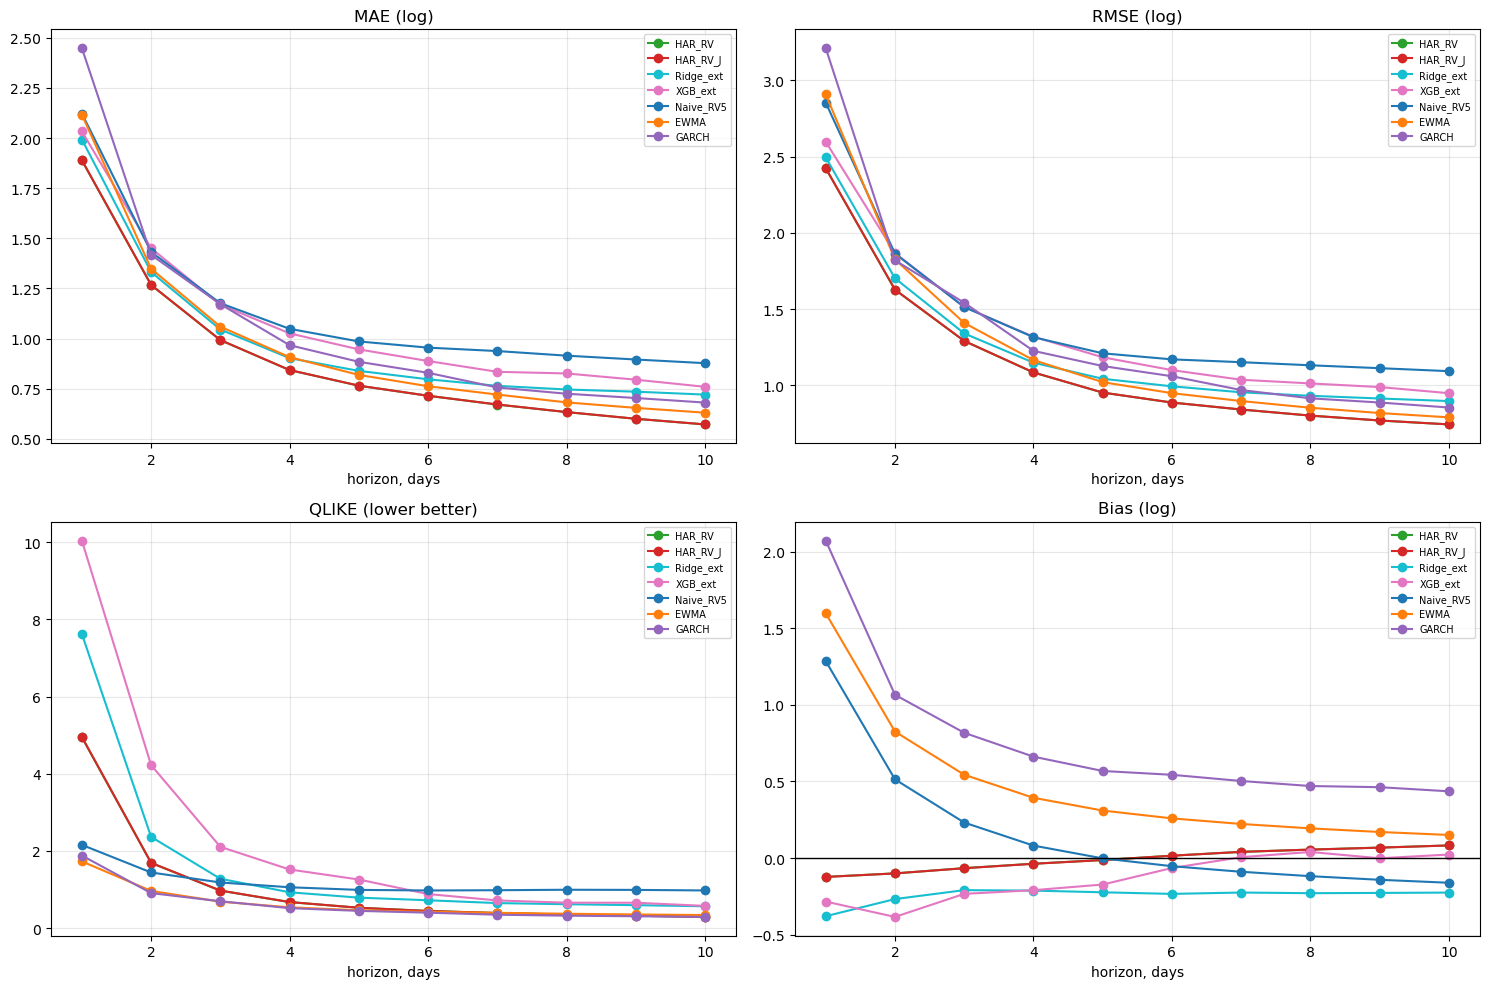


Best vol model by QLIKE: GARCH


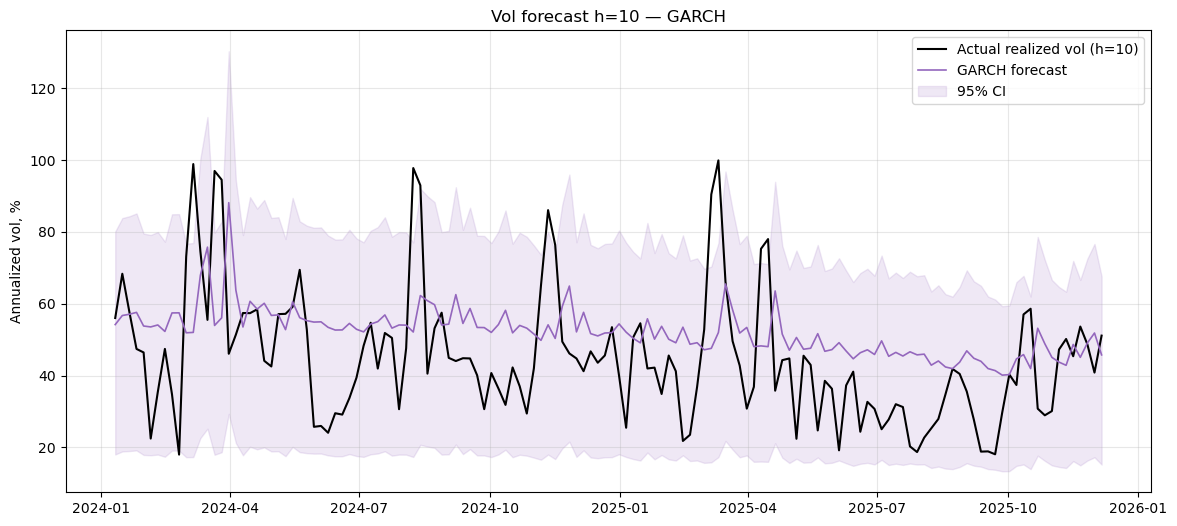

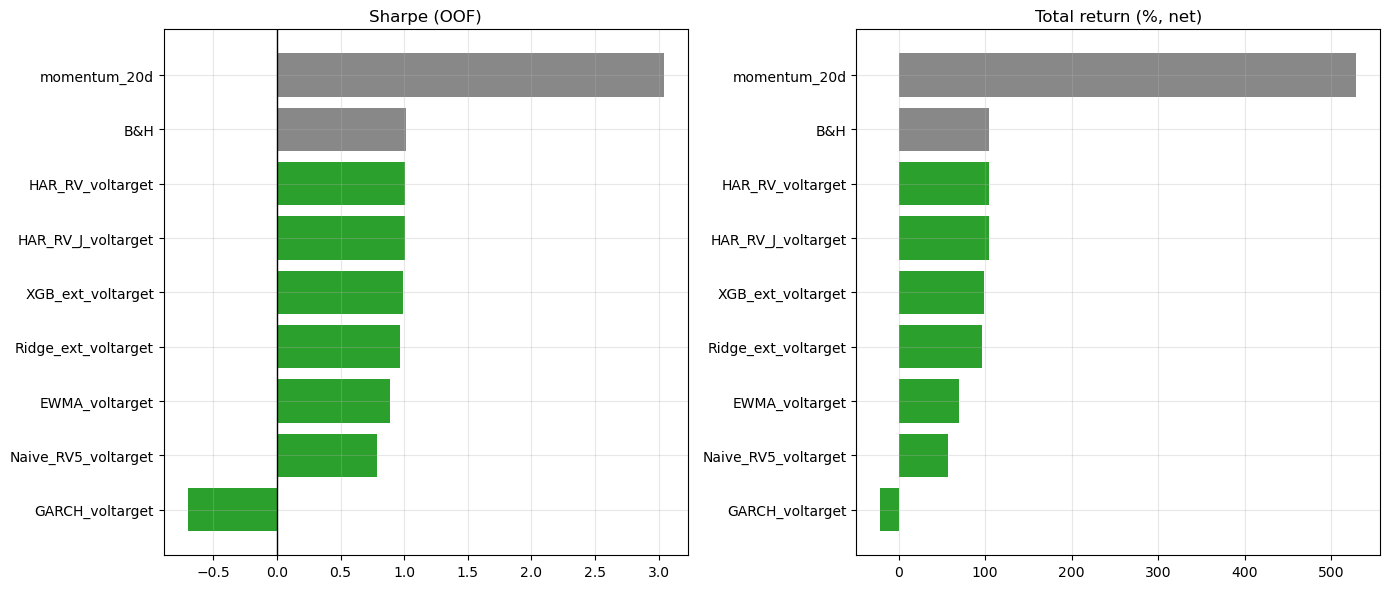


Saved v7.1 CSVs.

ИТОГИ v7.1

Vol metrics (все горизонты, sorted by QLIKE):
    model    n  MAE_log  RMSE_log  Bias_log  QLIKE
    GARCH 1400   1.0587    1.5233    0.7601 0.6115
     EWMA 7000   0.9704    1.4112    0.4668 0.6260
   HAR_RV 7000   0.8952    1.2477   -0.0074 1.0609
 HAR_RV_J 7000   0.8954    1.2479   -0.0078 1.0622
Naive_RV5 7000   1.1348    1.5339    0.1548 1.1747
Ridge_ext 7000   0.9878    1.3321   -0.2432 1.6130
  XGB_ext 7000   1.0731    1.4446   -0.1281 2.2637

Coverage 95% (avg per model):
model
EWMA         91.54
GARCH        88.71
HAR_RV       94.86
HAR_RV_J     94.87
Naive_RV5    93.14
Ridge_ext    95.33
XGB_ext      94.84

Backtest OOF:
                    total_ret_net_%    sharpe   sortino   max_dd_% exposure_%                model
momentum_20d             528.772489  3.039101       0.0 -12.320771  51.714286                  NaN
B&H                      104.544323  1.011264       0.0 -32.109069      100.0                  NaN
HAR_RV_voltarget         104.2428

In [11]:
"""
================================================================
BTC 10-day volatility forecast pipeline v7.1
================================================================
Исправления от v7:
  [FIX-1] target_date = origin + h, forecast_origin = origin (было наоборот)
          Устраняет look-ahead bias в backtest.
  [FIX-2] predicted_vol_daily = sqrt(exp(center) / h) (было exp(center/2/h))
  [FIX-3] GARCH cumulative variance = fc.variance.values[-1][:h].sum()
  [FIX-4] log_features_from_raw + dropna по признакам + nan_to_num
  [FIX-5] arch fit: try/except без show_warning
  [FIX-6] oof_vol не мутируется; calib merge делается в отдельный DataFrame
================================================================
"""

import os, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit

# ============================================================
# 0. Проверка зависимостей
# ============================================================
print("=" * 60)
print("Проверка зависимостей")
print("=" * 60)

HAVE_ARCH = False
HAVE_XGB  = False

try:
    from arch import arch_model
    HAVE_ARCH = True
    print("  [OK] arch")
except ImportError:
    print("  [MISSING] arch — pip install arch")

try:
    import xgboost as xgb
    HAVE_XGB = True
    print(f"  [OK] xgboost {xgb.__version__}")
except ImportError:
    print("  [MISSING] xgboost — fallback на HGB")

# ============================================================
# 1. Config
# ============================================================
CSV            = "crypto_daily_2022_2025_clean.csv"
EXOG_CACHE     = "exog_cache.csv"
CUTOFF         = pd.Timestamp("2025-11-30")
HOLDOUT_START  = pd.Timestamp("2025-12-01")
HOLDOUT_END    = pd.Timestamp("2025-12-31")
HORIZONS       = list(range(1, 11))
VAL_START      = pd.Timestamp("2024-01-01")
OOF_SPLITS     = 5

TARGET_VOL_ANNUAL = 0.40
TRADING_DAYS      = 365
BT_FEE_BPS        = 10
BT_SLIP_BPS       = 5

SAVE_FIGS = True
FIG_DIR   = "figs_v7"
np.random.seed(42)
if SAVE_FIGS: os.makedirs(FIG_DIR, exist_ok=True)

# ============================================================
# 2. Данные
# ============================================================
df_base = (pd.read_csv(CSV, parse_dates=["date"])
             .sort_values("date").reset_index(drop=True).ffill())
print(f"\nBase CSV: {df_base['date'].min().date()} … {df_base['date'].max().date()} "
      f"({len(df_base)} rows)")

if os.path.exists(EXOG_CACHE):
    exog = pd.read_csv(EXOG_CACHE, parse_dates=["date"]).set_index("date").sort_index()
    exog = exog.resample("D").last().ffill().shift(1)
    df = df_base.set_index("date").join(exog, how="left").reset_index()
    print(f"Exog: {exog.shape}, full={df.shape}")
else:
    df = df_base.copy()
    print("Exog not used")

# ============================================================
# 3. Признаки и цели
# ============================================================
def add_vol_features(d):
    d = d.copy()
    d["btc_ret"] = np.log(d["BTC"]).diff()
    d["eth_ret"] = np.log(d["ETH"]).diff()
    d["sol_ret"] = np.log(d["SOL"]).diff()
    d["r2"] = d["btc_ret"] ** 2

    # HAR components
    d["rv_d"] = d["r2"]
    d["rv_w"] = d["r2"].rolling(5).mean()
    d["rv_m"] = d["r2"].rolling(22).mean()

    # EWMA
    lam = 0.94
    ewma = np.zeros(len(d))
    r2v = d["r2"].values
    for i in range(1, len(d)):
        if np.isnan(r2v[i-1]):
            ewma[i] = ewma[i-1]
        else:
            ewma[i] = lam * ewma[i-1] + (1 - lam) * r2v[i-1]
    d["ewma_var"] = ewma
    d["ewma_vol"] = np.sqrt(d["ewma_var"])

    d["jump"] = np.maximum(d["r2"] - d["rv_w"], 0.0)
    d["neg_ret_lag1"] = (d["btc_ret"].shift(1) < 0).astype(float) * d["r2"].shift(1)

    d["rv_3"]  = d["r2"].rolling(3).mean()
    d["rv_10"] = d["r2"].rolling(10).mean()
    d["rv_60"] = d["r2"].rolling(60).mean()

    d["rv_ratio_d_w"] = d["rv_d"] / d["rv_w"]
    d["rv_ratio_w_m"] = d["rv_w"] / d["rv_m"]
    d["vol_of_vol_20"] = d["btc_ret"].rolling(20).std() / d["btc_ret"].rolling(60).std()

    for c in ["dxy", "t10y", "vix", "spx", "gold", "oil", "gtrends"]:
        if c in d.columns:
            d[f"{c}_ret"] = d[c].pct_change().replace([np.inf, -np.inf], np.nan)
            d[f"{c}_vol20"] = d[f"{c}_ret"].rolling(20).std()

    if "vix" in d.columns:
        d["vix_log"] = np.log(d["vix"].clip(lower=1))
        d["vix_ma5_ratio"] = d["vix"] / d["vix"].rolling(5).mean() - 1

    return d

df = add_vol_features(df)

# --- targets: y_h{h}[i] = sum r2 over (i, i+h] ---
r2 = df["r2"].values
for h in HORIZONS:
    y = np.full(len(df), np.nan)
    for i in range(len(df) - h):
        y[i] = np.nansum(r2[i+1:i+1+h])
    df[f"y_h{h}"] = np.where(y > 0, np.log(y), np.nan)

# --- feature sets ---
HAR_FEATURES   = ["rv_d", "rv_w", "rv_m"]
HAR_J_FEATURES = ["rv_d", "rv_w", "rv_m", "jump"]

EXT_FEATURES = [
    "rv_d", "rv_w", "rv_m", "rv_3", "rv_10", "rv_60",
    "jump", "ewma_var", "neg_ret_lag1",
    "rv_ratio_d_w", "rv_ratio_w_m", "vol_of_vol_20",
    "btc_ret", "eth_ret", "sol_ret",
]
for c in ["vix_log", "vix_ma5_ratio", "vix_ret", "vix_vol20",
          "dxy_ret", "dxy_vol20", "spx_ret", "spx_vol20",
          "gold_ret", "oil_ret", "gtrends_ret"]:
    if c in df.columns:
        EXT_FEATURES.append(c)
if "fear_greed" in df.columns:
    EXT_FEATURES.append("fear_greed")

# фильтруем колонки, которых реально нет
EXT_FEATURES = [c for c in EXT_FEATURES if c in df.columns]

print(f"HAR: {len(HAR_FEATURES)}, HAR+J: {len(HAR_J_FEATURES)}, Ext: {len(EXT_FEATURES)}")

# ============================================================
# 4. Split
# ============================================================
train   = df[df["date"] <= CUTOFF].reset_index(drop=True)
holdout = df[(df["date"] >= HOLDOUT_START) & (df["date"] <= HOLDOUT_END)].reset_index(drop=True)

origin_date  = train["date"].iloc[-1]
origin_price = float(train["BTC"].iloc[-1])
print(f"Origin: {origin_date.date()}, BTC={origin_price:,.2f}")
print(f"Train: {len(train)}, Holdout: {len(holdout)}")

train_oos_start = train[train["date"] >= VAL_START].index[0]
btc_prices_oos = train[["date", "BTC"]].iloc[train_oos_start:].reset_index(drop=True)

# ============================================================
# 5. Утилиты
# ============================================================
def log_features_from_raw(df_sub, cols, min_val=1e-12):
    """[FIX-4] log(rv_*) с обработкой NaN/inf."""
    out = {}
    for c in cols:
        v = df_sub[c].values.astype(float)
        v = np.nan_to_num(v, nan=min_val, posinf=min_val, neginf=min_val)
        out[f"log_{c}"] = np.log(np.maximum(v, min_val))
    return pd.DataFrame(out, index=df_sub.index)


def sanitize_X(X):
    """Финальный барьер от NaN/inf."""
    return np.nan_to_num(np.asarray(X, dtype=float), nan=0.0, posinf=0.0, neginf=0.0)


class HARModel(BaseEstimator, RegressorMixin):
    def __init__(self, alpha=1.0):
        self.alpha = alpha
    def fit(self, X, y):
        self.pipe_ = make_pipeline(StandardScaler(), Ridge(alpha=self.alpha))
        self.pipe_.fit(sanitize_X(X), np.nan_to_num(np.asarray(y, dtype=float)))
        return self
    def predict(self, X):
        return self.pipe_.predict(sanitize_X(X))


def garch_forecast_cumulative(y_ret, h, model_type="GARCH"):
    """
    [FIX-3] Возвращает log(cumulative variance over next h days).
    """
    if not HAVE_ARCH:
        return None
    try:
        y_pct = y_ret * 100
        if model_type == "GARCH":
            am = arch_model(y_pct, vol="Garch", p=1, q=1, dist="Normal")
        elif model_type == "EGARCH":
            am = arch_model(y_pct, vol="EGARCH", p=1, o=1, q=1, dist="Normal")
        else:
            return None

        # [FIX-5] show_warning может отсутствовать в некоторых версиях
        try:
            res = am.fit(disp="off", show_warning=False)
        except TypeError:
            res = am.fit(disp="off")

        fc = res.forecast(horizon=10, reindex=False)
        var_path = fc.variance.values[-1]     # shape (10,), variance for days 1..10
        var_sum = float(np.sum(var_path[:h])) / 1e4   # % → decimal
        if var_sum <= 0 or not np.isfinite(var_sum):
            return None
        return float(np.log(var_sum))
    except Exception:
        return None

# ============================================================
# 6. OOF
# ============================================================
def run_oof_vol(df_train, horizons, val_start, n_splits):
    """
    [FIX-1] target_date = origin + h; forecast_origin = origin.
    """
    price_map = dict(zip(df_train["date"], df_train["BTC"]))
    rows = []

    tscv = TimeSeriesSplit(n_splits=n_splits)
    splits = list(tscv.split(df_train))

    sklearn_specs = {
        "HAR_RV":    (HAR_FEATURES,   "log"),
        "HAR_RV_J":  (HAR_J_FEATURES, "log"),
        "Ridge_ext": (EXT_FEATURES,   "raw"),
        "XGB_ext":   (EXT_FEATURES,   "raw"),
    }

    for model_name, (feat_cols, mode) in sklearn_specs.items():
        print(f"\n--- {model_name} ---")
        feat_cols = list(feat_cols)
        for h in tqdm(horizons, desc=model_name):
            y_col = f"y_h{h}"
            for tr_pos, te_pos in splits:
                tr_end = te_pos[0] - h
                if tr_end <= 200: continue
                tr_pos_clean = tr_pos[tr_pos < tr_end]
                if len(tr_pos_clean) < 200: continue

                # [FIX-4] dropna по y и признакам + sanitize
                tr = df_train.iloc[tr_pos_clean].replace([np.inf, -np.inf], np.nan)
                tr = tr.dropna(subset=[y_col] + feat_cols)
                if len(tr) < 200: continue

                if mode == "log":
                    X_tr = log_features_from_raw(tr, feat_cols).values
                else:
                    X_tr = tr[feat_cols].astype(float).values
                X_tr = sanitize_X(X_tr)
                y_tr = np.nan_to_num(tr[y_col].values, nan=0.0)

                if model_name in ("HAR_RV", "HAR_RV_J"):
                    m = HARModel(alpha=1.0)
                elif model_name == "Ridge_ext":
                    m = make_pipeline(StandardScaler(), Ridge(alpha=10.0))
                elif model_name == "XGB_ext":
                    if HAVE_XGB:
                        m = xgb.XGBRegressor(n_estimators=200, max_depth=4,
                                             learning_rate=0.05, subsample=0.8,
                                             colsample_bytree=0.8, random_state=42,
                                             n_jobs=-1, verbosity=0)
                    else:
                        m = HistGradientBoostingRegressor(max_iter=200,
                                                          learning_rate=0.05,
                                                          random_state=42)
                else:
                    continue

                m.fit(X_tr, y_tr)

                te = df_train.iloc[te_pos].replace([np.inf, -np.inf], np.nan)
                te = te[te["date"] >= val_start]
                te = te.dropna(subset=[y_col] + feat_cols)
                if len(te) == 0: continue

                if mode == "log":
                    X_te = log_features_from_raw(te, feat_cols).values
                else:
                    X_te = te[feat_cols].astype(float).values
                X_te = sanitize_X(X_te)

                pred = m.predict(X_te)

                for i, (_, r) in enumerate(te.iterrows()):
                    origin = r["date"]
                    target = origin + pd.Timedelta(days=h)
                    rows.append({
                        "model": model_name,
                        "horizon_days": h,
                        "forecast_origin": origin,
                        "target_date": target,
                        "current_close": float(r["BTC"]),
                        "predicted_log_var": float(pred[i]),
                        "actual_log_var": float(r[y_col]),
                    })

    # Naive RV5 / EWMA — тут semantics уже правильные
    for h in horizons:
        y_col = f"y_h{h}"
        for _, r in df_train.iterrows():
            if r["date"] < val_start: continue
            if pd.isna(r[y_col]): continue
            origin = r["date"]
            target = origin + pd.Timedelta(days=h)
            if not pd.isna(r["rv_w"]):
                rv5 = float(r["rv_w"]) * h
                rows.append({
                    "model": "Naive_RV5", "horizon_days": h,
                    "forecast_origin": origin, "target_date": target,
                    "current_close": float(r["BTC"]),
                    "predicted_log_var": float(np.log(max(rv5, 1e-12))),
                    "actual_log_var": float(r[y_col]),
                })
            if not pd.isna(r["ewma_var"]):
                ew = float(r["ewma_var"]) * h
                rows.append({
                    "model": "EWMA", "horizon_days": h,
                    "forecast_origin": origin, "target_date": target,
                    "current_close": float(r["BTC"]),
                    "predicted_log_var": float(np.log(max(ew, 1e-12))),
                    "actual_log_var": float(r[y_col]),
                })

    # GARCH / EGARCH
    if HAVE_ARCH:
        print("\n--- GARCH / EGARCH ---")
        val_dates = df_train[df_train["date"] >= val_start]["date"].tolist()[::5]
        for d in tqdm(val_dates, desc="GARCH/EGARCH"):
            idx = df_train.index[df_train["date"] == d][0]
            if idx < 250: continue
            hist = df_train.iloc[max(0, idx-1000):idx]
            y_hist = hist["btc_ret"].dropna().values
            if len(y_hist) < 200: continue

            for mt in ["GARCH", "EGARCH"]:
                cur = float(df_train.iloc[idx]["BTC"])
                for h in horizons:
                    pred_log = garch_forecast_cumulative(y_hist, h, model_type=mt)
                    if pred_log is None: continue
                    y_col = f"y_h{h}"
                    actual = float(df_train.iloc[idx][y_col])
                    if pd.isna(actual): continue
                    rows.append({
                        "model": mt, "horizon_days": h,
                        "forecast_origin": d,
                        "target_date": d + pd.Timedelta(days=h),
                        "current_close": cur,
                        "predicted_log_var": pred_log,
                        "actual_log_var": actual,
                    })

    out = pd.DataFrame(rows).dropna(subset=["actual_log_var"]).reset_index(drop=True)
    return out

# ============================================================
# 7. Метрики
# ============================================================
def qlike_loss(actual_log_var, pred_log_var):
    y = np.exp(actual_log_var)
    p = np.exp(pred_log_var)
    ratio = y / p
    return float(np.mean(ratio - np.log(ratio) - 1))

def vol_metrics(fc, by="model"):
    rows = []
    for (m, h), g in fc.groupby([by, "horizon_days"]):
        err_log = g["predicted_log_var"] - g["actual_log_var"]
        rows.append({
            "model": m, "horizon": h, "n": len(g),
            "MAE_log":  float(np.mean(np.abs(err_log))),
            "RMSE_log": float(np.sqrt(np.mean(err_log ** 2))),
            "Bias_log": float(np.mean(err_log)),
            "QLIKE":    qlike_loss(g["actual_log_var"].values,
                                    g["predicted_log_var"].values),
        })
    return pd.DataFrame(rows).sort_values(["model", "horizon"]).reset_index(drop=True)

def vol_overall(fc, h_subset=None):
    g_all = fc.copy()
    if h_subset is not None:
        g_all = g_all[g_all["horizon_days"].isin(h_subset)]
    rows = []
    for m, g in g_all.groupby("model"):
        err_log = g["predicted_log_var"] - g["actual_log_var"]
        rows.append({
            "model": m, "n": len(g),
            "MAE_log":  float(np.mean(np.abs(err_log))),
            "RMSE_log": float(np.sqrt(np.mean(err_log ** 2))),
            "Bias_log": float(np.mean(err_log)),
            "QLIKE":    qlike_loss(g["actual_log_var"].values,
                                    g["predicted_log_var"].values),
        })
    return pd.DataFrame(rows).sort_values("QLIKE").reset_index(drop=True)

# ============================================================
# 8. RUN OOF
# ============================================================
print("\n" + "=" * 60)
print("RUN OOF volatility")
print("=" * 60)

oof_vol_raw = run_oof_vol(train, HORIZONS, VAL_START, OOF_SPLITS)
print(f"\nOOF vol rows: {len(oof_vol_raw)}, models: {sorted(oof_vol_raw['model'].unique())}")

print("\nOverall vol metrics:")
print(vol_overall(oof_vol_raw).round(4).to_string(index=False))

print("\nVol metrics h=1-3:")
print(vol_overall(oof_vol_raw, h_subset=range(1,4)).round(4).to_string(index=False))

print("\nVol metrics h=8-10:")
print(vol_overall(oof_vol_raw, h_subset=range(8,11)).round(4).to_string(index=False))

# ============================================================
# 9. Калибровка интервалов
# ============================================================
calib_rows = []
for (m, h), g in oof_vol_raw.groupby(["model", "horizon_days"]):
    err = (g["actual_log_var"] - g["predicted_log_var"]).values
    n = len(err)
    if n < 30: continue
    calib_rows.append({
        "model": m, "horizon_days": h,
        "bias":  float(np.mean(err)),
        "sigma": float(np.std(err, ddof=1)),
        "q025":  float(np.quantile(err, 0.025)),
        "q975":  float(np.quantile(err, 0.975)),
        "n_oof": n,
    })
calib = pd.DataFrame(calib_rows)

# [FIX-6] не мутируем oof_vol_raw; делаем отдельный DataFrame
oof_vol = oof_vol_raw.merge(calib, on=["model", "horizon_days"], how="left")
oof_vol["log_var_center"] = oof_vol["predicted_log_var"] + oof_vol["bias"].fillna(0)
oof_vol["ci_low"]  = oof_vol["log_var_center"] + oof_vol["q025"]
oof_vol["ci_high"] = oof_vol["log_var_center"] + oof_vol["q975"]
oof_vol["covered"] = ((oof_vol["actual_log_var"] >= oof_vol["ci_low"]) &
                       (oof_vol["actual_log_var"] <= oof_vol["ci_high"]))

cov_stats = (oof_vol.groupby(["model", "horizon_days"])["covered"].mean()
                    .reset_index())
cov_stats.columns = ["model", "horizon", "coverage_%"]
cov_stats["coverage_%"] *= 100

print("\nCoverage 95% (avg per model):")
print(cov_stats.groupby("model")["coverage_%"].mean().round(2).to_string())

# ============================================================
# 10. Финальный прогноз от origin
# ============================================================
print("\n" + "=" * 60)
print("FINAL vol forecast from 2025-11-30")
print("=" * 60)

final_rows = []

for model_name, feat_cols, mode in [
    ("HAR_RV",    HAR_FEATURES,   "log"),
    ("HAR_RV_J",  HAR_J_FEATURES, "log"),
    ("Ridge_ext", EXT_FEATURES,   "raw"),
    ("XGB_ext",   EXT_FEATURES,   "raw"),
]:
    feat_cols = list(feat_cols)
    for h in HORIZONS:
        y_col = f"y_h{h}"
        tr = train.iloc[:len(train) - h].replace([np.inf, -np.inf], np.nan)
        tr = tr.dropna(subset=[y_col] + feat_cols)
        if len(tr) < 200: continue

        if mode == "log":
            X_tr = log_features_from_raw(tr, feat_cols).values
        else:
            X_tr = tr[feat_cols].astype(float).values
        X_tr = sanitize_X(X_tr)
        y_tr = np.nan_to_num(tr[y_col].values, nan=0.0)

        if model_name in ("HAR_RV", "HAR_RV_J"):
            m = HARModel(alpha=1.0)
        elif model_name == "Ridge_ext":
            m = make_pipeline(StandardScaler(), Ridge(alpha=10.0))
        elif model_name == "XGB_ext":
            if HAVE_XGB:
                m = xgb.XGBRegressor(n_estimators=200, max_depth=4,
                                     learning_rate=0.05, subsample=0.8,
                                     colsample_bytree=0.8, random_state=42,
                                     n_jobs=-1, verbosity=0)
            else:
                m = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05,
                                                  random_state=42)

        m.fit(X_tr, y_tr)

        # origin row
        origin_row = train.iloc[[-1]].replace([np.inf, -np.inf], np.nan)
        if mode == "log":
            X_now = log_features_from_raw(origin_row, feat_cols).values
        else:
            X_now = origin_row[feat_cols].astype(float).values
        X_now = sanitize_X(X_now)

        pred_log = float(m.predict(X_now)[0])

        cal_row = calib[(calib["model"] == model_name) &
                         (calib["horizon_days"] == h)]
        if len(cal_row) == 0: continue
        cal_row = cal_row.iloc[0]
        center = pred_log + cal_row["bias"]
        ci_low  = center + cal_row["q025"]
        ci_high = center + cal_row["q975"]

        # [FIX-2] корректная формула
        daily_var = np.exp(center) / h
        daily_vol = np.sqrt(daily_var)
        ann_vol   = np.sqrt(daily_var * TRADING_DAYS) * 100
        ann_vol_lo = np.sqrt(np.exp(ci_low) / h * TRADING_DAYS) * 100
        ann_vol_hi = np.sqrt(np.exp(ci_high) / h * TRADING_DAYS) * 100

        final_rows.append({
            "model": model_name, "horizon_days": h,
            "target_date": origin_date + pd.Timedelta(days=h),
            "predicted_log_var": center,
            "predicted_vol_daily":  float(daily_vol),
            "predicted_vol_annual_%": float(ann_vol),
            "ci_vol_annual_low_%":  float(ann_vol_lo),
            "ci_vol_annual_high_%": float(ann_vol_hi),
        })

# Naive / EWMA
for model_name, col_name in [("Naive_RV5", "rv_w"), ("EWMA", "ewma_var")]:
    base_val = float(train[col_name].iloc[-1])
    for h in HORIZONS:
        pred_log = float(np.log(max(base_val * h, 1e-12)))
        cal_row = calib[(calib["model"] == model_name) &
                         (calib["horizon_days"] == h)]
        if len(cal_row) == 0: continue
        cal_row = cal_row.iloc[0]
        center = pred_log + cal_row["bias"]
        ci_low  = center + cal_row["q025"]
        ci_high = center + cal_row["q975"]

        daily_var = np.exp(center) / h
        final_rows.append({
            "model": model_name, "horizon_days": h,
            "target_date": origin_date + pd.Timedelta(days=h),
            "predicted_log_var": center,
            "predicted_vol_daily":  float(np.sqrt(daily_var)),
            "predicted_vol_annual_%": float(np.sqrt(daily_var * TRADING_DAYS) * 100),
            "ci_vol_annual_low_%":  float(np.sqrt(np.exp(ci_low) / h * TRADING_DAYS) * 100),
            "ci_vol_annual_high_%": float(np.sqrt(np.exp(ci_high) / h * TRADING_DAYS) * 100),
        })

final_vol = pd.DataFrame(final_rows)


def realized_vol_annual(df_all, date, h):
    sub = df_all[(df_all["date"] > date) & (df_all["date"] <= date + pd.Timedelta(days=h))]
    if len(sub) < max(2, int(h * 0.7)): return np.nan
    r = sub["btc_ret"].dropna().values
    if len(r) < 2: return np.nan
    var_sum = float(np.sum(r ** 2))
    return float(np.sqrt(var_sum / h * TRADING_DAYS) * 100)


final_vol["actual_vol_annual_%"] = [
    realized_vol_annual(df, origin_date, h)
    for h in final_vol["horizon_days"]
]

print(final_vol.round(2).to_string(index=False))

# ============================================================
# 11. Vol targeting backtest
# ============================================================
print("\n" + "=" * 60)
print("Vol targeting backtest (OOF)")
print("=" * 60)

def vol_target_backtest(fc_h1, prices_df, target_vol_annual=TARGET_VOL_ANNUAL,
                         fee_bps=BT_FEE_BPS, slip_bps=BT_SLIP_BPS):
    p = prices_df.set_index("date")["BTC"].sort_index()
    btc_ret = p.pct_change().fillna(0)

    fc = fc_h1.set_index("target_date").sort_index()
    fc_var = np.exp(fc["predicted_log_var"])
    fc_daily_vol = np.sqrt(fc_var)

    target_daily_vol = target_vol_annual / np.sqrt(TRADING_DAYS)
    position = (target_daily_vol / fc_daily_vol).clip(upper=1.0)
    position = position.reindex(p.index).fillna(0)

    gross = position * btc_ret
    trades = position.diff().abs().fillna(0)
    cost = trades * (fee_bps + slip_bps) / 1e4
    net = gross - cost
    equity = (1 + net).cumprod()

    if len(equity) == 0 or equity.iloc[-1] <= 0:
        return None

    total = equity.iloc[-1] - 1
    dd = (equity / equity.cummax() - 1).min()
    mu, sd = net.mean(), net.std()
    sharpe = mu / sd * np.sqrt(TRADING_DAYS) if sd > 0 else 0
    down = net[net < 0].std()
    sortino = mu / down * np.sqrt(TRADING_DAYS) if down > 0 else 0

    return {
        "total_ret_net_%": total * 100,
        "sharpe": sharpe,
        "sortino": sortino,
        "max_dd_%": dd * 100,
        "exposure_%": position.mean() * 100,
    }

def bh_backtest(prices_df):
    p = prices_df.set_index("date")["BTC"].sort_index()
    btc_ret = p.pct_change().fillna(0)
    eq = (1 + btc_ret).cumprod()
    total = eq.iloc[-1] - 1
    dd = (eq / eq.cummax() - 1).min()
    mu, sd = btc_ret.mean(), btc_ret.std()
    sharpe = mu / sd * np.sqrt(TRADING_DAYS) if sd > 0 else 0
    return {"total_ret_net_%": total * 100, "sharpe": sharpe, "sortino": 0,
            "max_dd_%": dd * 100, "exposure_%": 100.0}

def momentum_backtest(prices_df, window=20, fee_bps=10, slip_bps=5):
    p = prices_df.set_index("date")["BTC"].sort_index()
    btc_ret = p.pct_change().fillna(0)
    mom = (p.pct_change(window) > 0).astype(float).reindex(p.index).fillna(0)
    gross = mom * btc_ret
    trades = mom.diff().abs().fillna(0)
    cost = trades * (fee_bps + slip_bps) / 1e4
    net = gross - cost
    eq = (1 + net).cumprod()
    total = eq.iloc[-1] - 1
    dd = (eq / eq.cummax() - 1).min()
    mu, sd = net.mean(), net.std()
    sharpe = mu / sd * np.sqrt(TRADING_DAYS) if sd > 0 else 0
    return {"total_ret_net_%": total * 100, "sharpe": sharpe, "sortino": 0,
            "max_dd_%": dd * 100, "exposure_%": mom.mean() * 100}

bt_results = {}
for m in oof_vol["model"].unique():
    fc_h1 = oof_vol[(oof_vol["model"] == m) & (oof_vol["horizon_days"] == 1)].copy()
    if len(fc_h1) < 50: continue
    try:
        bt = vol_target_backtest(fc_h1, btc_prices_oos)
        if bt is not None:
            bt["model"] = f"{m}_voltarget"
            bt_results[f"{m}_voltarget"] = bt
    except Exception as e:
        print(f"  [skip] {m}: {e}")

bt_results["B&H"] = bh_backtest(btc_prices_oos)
bt_results["momentum_20d"] = momentum_backtest(btc_prices_oos)

bt_df = pd.DataFrame(bt_results).T.sort_values("sharpe", ascending=False)
print(bt_df.round(3).to_string())

# ============================================================
# 12. Plots
# ============================================================
colors = {
    "Naive_RV5": "#1f77b4", "EWMA": "#ff7f0e",
    "HAR_RV": "#2ca02c", "HAR_RV_J": "#d62728",
    "GARCH": "#9467bd", "EGARCH": "#8c564b",
    "Ridge_ext": "#17becf", "XGB_ext": "#e377c2",
}

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sub_metrics = vol_metrics(oof_vol)
for m in oof_vol["model"].unique():
    sub = sub_metrics[sub_metrics["model"] == m].sort_values("horizon")
    if len(sub) == 0: continue
    col = colors.get(m, "grey")
    axes[0,0].plot(sub["horizon"], sub["MAE_log"],  marker="o", color=col, label=m)
    axes[0,1].plot(sub["horizon"], sub["RMSE_log"], marker="o", color=col, label=m)
    axes[1,0].plot(sub["horizon"], sub["QLIKE"],    marker="o", color=col, label=m)
    axes[1,1].plot(sub["horizon"], sub["Bias_log"], marker="o", color=col, label=m)

axes[0,0].set_title("MAE (log)")
axes[0,1].set_title("RMSE (log)")
axes[1,0].set_title("QLIKE (lower better)")
axes[1,1].set_title("Bias (log)"); axes[1,1].axhline(0, color="k", lw=1)
for ax in axes.flat:
    ax.set_xlabel("horizon, days"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
plt.tight_layout()
if SAVE_FIGS: plt.savefig(f"{FIG_DIR}/vol_metrics_by_horizon.png", dpi=130, bbox_inches="tight")
plt.show()

best_model = vol_overall(oof_vol).iloc[0]["model"]
print(f"\nBest vol model by QLIKE: {best_model}")
sub = oof_vol[(oof_vol["model"] == best_model) & (oof_vol["horizon_days"] == 10)] \
        .sort_values("target_date")
if len(sub) > 0:
    fig, ax = plt.subplots(figsize=(14, 6))
    actual_vol = np.sqrt(np.exp(sub["actual_log_var"].values) / 10 * TRADING_DAYS) * 100
    pred_vol   = np.sqrt(np.exp(sub["predicted_log_var"].values) / 10 * TRADING_DAYS) * 100
    ci_lo      = np.sqrt(np.exp(sub["ci_low"].values) / 10 * TRADING_DAYS) * 100
    ci_hi      = np.sqrt(np.exp(sub["ci_high"].values) / 10 * TRADING_DAYS) * 100
    ax.plot(sub["target_date"], actual_vol, "k-", lw=1.5, label="Actual realized vol (h=10)")
    ax.plot(sub["target_date"], pred_vol, "-", color=colors.get(best_model, "green"),
            lw=1.2, label=f"{best_model} forecast")
    ax.fill_between(sub["target_date"], ci_lo, ci_hi, alpha=0.15,
                     color=colors.get(best_model, "green"), label="95% CI")
    ax.set_title(f"Vol forecast h=10 — {best_model}")
    ax.set_ylabel("Annualized vol, %"); ax.grid(alpha=0.3); ax.legend()
    if SAVE_FIGS: plt.savefig(f"{FIG_DIR}/vol_forecast_h10.png", dpi=130, bbox_inches="tight")
    plt.show()

if len(bt_df) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    bt_plot = bt_df.reset_index()
    name_col = bt_plot.columns[0]
    cols = ["#2ca02c" if "voltarget" in n else "#888888" for n in bt_plot[name_col]]
    axes[0].barh(bt_plot[name_col], bt_plot["sharpe"], color=cols)
    axes[0].axvline(0, color="k", lw=1)
    axes[0].set_title("Sharpe (OOF)")
    axes[0].invert_yaxis(); axes[0].grid(alpha=0.3)
    axes[1].barh(bt_plot[name_col], bt_plot["total_ret_net_%"], color=cols)
    axes[1].set_title("Total return (%, net)")
    axes[1].invert_yaxis(); axes[1].grid(alpha=0.3)
    plt.tight_layout()
    if SAVE_FIGS: plt.savefig(f"{FIG_DIR}/vol_backtest.png", dpi=130, bbox_inches="tight")
    plt.show()

# ============================================================
# 13. Export
# ============================================================
oof_vol_raw.to_csv("oof_vol_v71.csv", index=False)
vol_metrics(oof_vol).to_csv("vol_metrics_v71.csv", index=False)
vol_overall(oof_vol).to_csv("vol_overall_v71.csv", index=False)
cov_stats.to_csv("vol_coverage_v71.csv", index=False)
final_vol.to_csv("final_vol_forecast_v71.csv", index=False)
bt_df.to_csv("backtest_vol_v71.csv")
calib.to_csv("vol_calibration_v71.csv", index=False)

print("\nSaved v7.1 CSVs.")

# ============================================================
# 14. Итоги
# ============================================================
print("\n" + "=" * 60)
print("ИТОГИ v7.1")
print("=" * 60)
print("\nVol metrics (все горизонты, sorted by QLIKE):")
print(vol_overall(oof_vol).round(4).to_string(index=False))

print("\nCoverage 95% (avg per model):")
print(cov_stats.groupby("model")["coverage_%"].mean().round(2).to_string())

print("\nBacktest OOF:")
print(bt_df.round(3).to_string())

bh_sharpe = bt_df.loc["B&H", "sharpe"]
vol_models = [m for m in bt_df.index if "voltarget" in m]
better = [m for m in vol_models if bt_df.loc[m, "sharpe"] > bh_sharpe]
print(f"\nB&H Sharpe: {bh_sharpe:.3f}")
if better:
    print(f"Vol-targeting beats B&H on Sharpe: {better}")
else:
    print("Ни одна vol-targeting модель не обошла B&H по Sharpe.")
    print("Но смотрите на Max DD — vol targeting обычно даёт меньшую просадку.")

print("\nФинальный прогноз vol на декабрь:")
print(final_vol[["model", "horizon_days",
                  "predicted_vol_annual_%",
                  "ci_vol_annual_low_%", "ci_vol_annual_high_%",
                  "actual_vol_annual_%"]].round(2).to_string(index=False))

Train: 1430, OOS: 700
OOS: 2024-01-01 … 2025-11-30

Walk-forward HAR_RV OOF:
rows: 1400, h-values: [np.int64(1), np.int64(10)]

Signals: 1430 rows, 2022-01-01 … 2025-11-30
HAR vol: mean=19.6%, median=19.3%
EWMA vol: mean=49.4%, median=47.0%

GRID SEARCH vol targeting

Всего экспериментов: 82

Top-15 по Sharpe:
       model     target_mode  target_level sizing  max_lev  total_ret_%  sharpe  max_dd_%  exposure_%  turnover
momentum_20d               -           NaN      -      NaN     4213.697   2.995   -12.321      52.168   160.000
         HAR           fixed          0.40 linear      1.0      113.575   0.739   -32.109      48.951     1.000
         HAR           fixed          0.40   sqrt      1.0      113.575   0.739   -32.109      48.951     1.000
         HAR           fixed          0.30   sqrt      1.0      111.244   0.733   -32.109      48.925     1.487
         HAR           fixed          0.30 linear      1.0      109.099   0.727   -32.109      48.901     1.944
         HAR    

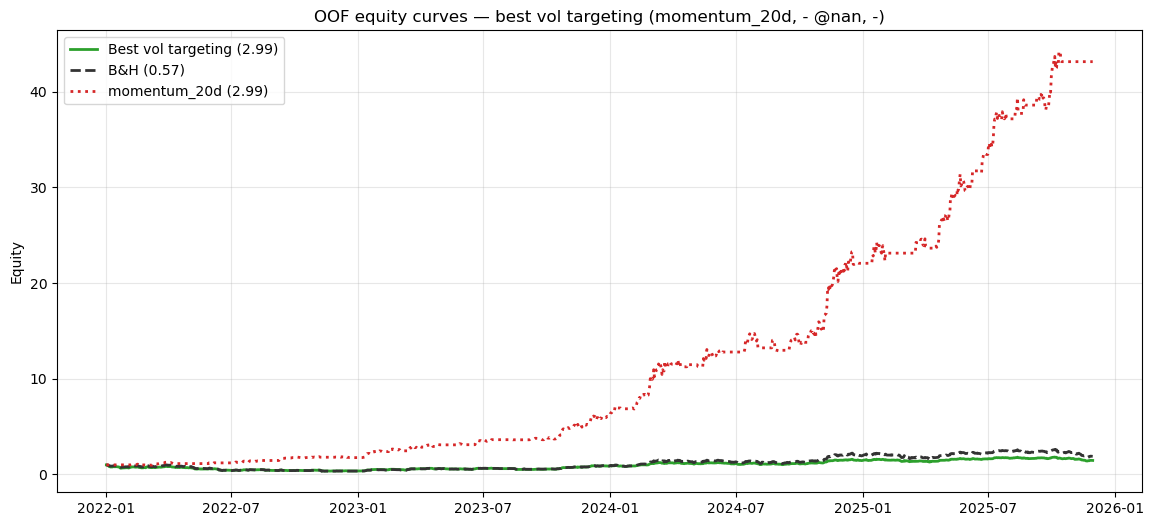

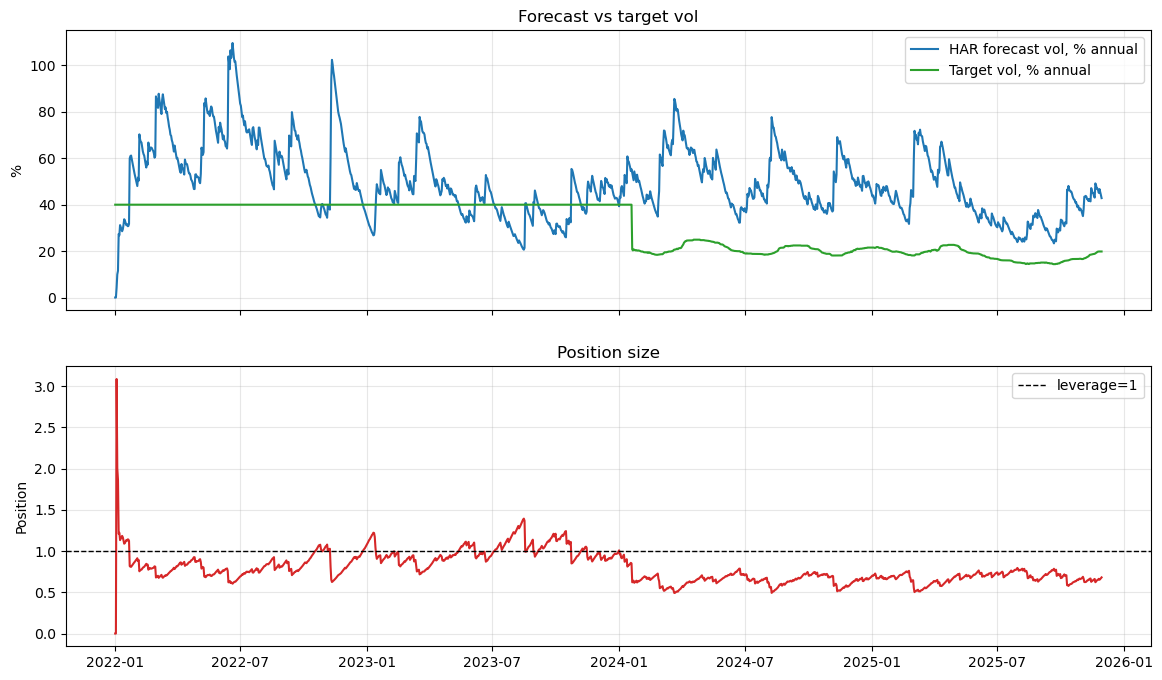


ИТОГИ v7.2

B&H Sharpe:       0.573
momentum Sharpe:  2.995
Best vol Sharpe:  2.995 (momentum_20d / -)

→ Vol targeting обошёл B&H, но не momentum.

Лучший vol targeting vs B&H:
  Sharpe:  0.739 vs 0.573
  Return:  113.57% vs 89.17%
  Max DD:  -32.11% vs -67.00%
  Exposure: 49.0% vs 100%

Saved: v72_grid.csv


In [12]:
"""
================================================================
BTC volatility targeting pipeline v7.2
================================================================
Цель: проверить, даёт ли vol targeting с АДАПТИВНЫМ target
      преимущество над B&H и momentum_20d.

Гипотезы, которые проверяем:
  H1: Fixed target 40% слишком высок для BTC → вырождается в B&H.
  H2: Adaptive target = rolling median(forecast) даст разумную экспозицию.
  H3: Sqrt-sizing (мягче, чем linear) стабильнее на шуме.
  H4: Ограничение leverage < 1 защищает от переоценки vol.

Сетка экспериментов:
  target_mode ∈ {fixed, adaptive_median, adaptive_pct}
  target_level ∈ {0.15, 0.20, 0.25, 0.30, 0.40}
  sizing ∈ {linear, sqrt}
  max_leverage ∈ {1.0, 1.5}

Результат: таблица Sharpe/DD/exposure по всем комбинациям + финальная рекомендация.
================================================================
"""

import os, warnings, itertools
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# ============================================================
# Config
# ============================================================
CSV            = "crypto_daily_2022_2025_clean.csv"
EXOG_CACHE     = "exog_cache.csv"
CUTOFF         = pd.Timestamp("2025-11-30")
VAL_START      = pd.Timestamp("2024-01-01")
TRADING_DAYS   = 365
BT_FEE_BPS     = 10
BT_SLIP_BPS    = 5

# Сетка экспериментов
TARGET_MODES    = ["fixed", "adaptive_median", "adaptive_pct"]
TARGET_LEVELS   = [0.15, 0.20, 0.25, 0.30, 0.40]
SIZING_MODES    = ["linear", "sqrt"]
MAX_LEVERAGES   = [1.0, 1.5]

# Adaptive target params
ADAPTIVE_LOOKBACK = 60     # дней
ADAPTIVE_PCT      = 0.5    # медиана (для adaptive_pct = 0.5)

SAVE_FIGS = True
FIG_DIR   = "figs_v72"
np.random.seed(42)
if SAVE_FIGS: os.makedirs(FIG_DIR, exist_ok=True)

# ============================================================
# 1. Данные и признаки (компактно, как в v7.1)
# ============================================================
df_base = (pd.read_csv(CSV, parse_dates=["date"])
             .sort_values("date").reset_index(drop=True).ffill())

if os.path.exists(EXOG_CACHE):
    exog = pd.read_csv(EXOG_CACHE, parse_dates=["date"]).set_index("date").sort_index()
    exog = exog.resample("D").last().ffill().shift(1)
    df = df_base.set_index("date").join(exog, how="left").reset_index()
else:
    df = df_base.copy()

def add_vol_features(d):
    d = d.copy()
    d["btc_ret"] = np.log(d["BTC"]).diff()
    d["r2"] = d["btc_ret"] ** 2
    d["rv_d"] = d["r2"]
    d["rv_w"] = d["r2"].rolling(5).mean()
    d["rv_m"] = d["r2"].rolling(22).mean()
    # EWMA
    lam = 0.94
    ewma = np.zeros(len(d)); r2v = d["r2"].values
    for i in range(1, len(d)):
        if np.isnan(r2v[i-1]): ewma[i] = ewma[i-1]
        else: ewma[i] = lam * ewma[i-1] + (1 - lam) * r2v[i-1]
    d["ewma_var"] = ewma
    return d

df = add_vol_features(df)

# targets: log(sum r2 over next h days)
r2 = df["r2"].values
for h in [1, 5, 10]:
    y = np.full(len(df), np.nan)
    for i in range(len(df) - h):
        y[i] = np.nansum(r2[i+1:i+1+h])
    df[f"y_h{h}"] = np.where(y > 0, np.log(y), np.nan)

HAR_FEATURES = ["rv_d", "rv_w", "rv_m"]

train = df[df["date"] <= CUTOFF].reset_index(drop=True)
oos   = train[train["date"] >= VAL_START].reset_index(drop=True)

print(f"Train: {len(train)}, OOS: {len(oos)}")
print(f"OOS: {oos['date'].min().date()} … {oos['date'].max().date()}")

# ============================================================
# 2. Обучаем HAR_RV для каждого h (walk-forward OOF на OOS)
# ============================================================
def log_features(d, cols, min_val=1e-12):
    out = {}
    for c in cols:
        v = np.nan_to_num(d[c].values.astype(float), nan=min_val,
                          posinf=min_val, neginf=min_val)
        out[f"log_{c}"] = np.log(np.maximum(v, min_val))
    return pd.DataFrame(out, index=d.index)

class HARModel(BaseEstimator, RegressorMixin):
    def __init__(self, alpha=1.0): self.alpha = alpha
    def fit(self, X, y):
        self.pipe_ = make_pipeline(StandardScaler(), Ridge(alpha=self.alpha))
        self.pipe_.fit(np.nan_to_num(X, nan=0.0), y)
        return self
    def predict(self, X):
        return self.pipe_.predict(np.nan_to_num(X, nan=0.0))

def walk_forward_har(df_train, horizons, val_start):
    """Для каждой OOS-точки — прогноз log-var на горизонт h (walk-forward)."""
    rows = []
    y_cols = [f"y_h{h}" for h in horizons]

    for idx in range(len(df_train)):
        d = df_train.iloc[idx]["date"]
        if d < val_start: continue

        for h in horizons:
            y_col = f"y_h{h}"
            # train = все точки до idx-h (purge)
            tr_end = idx - h
            if tr_end < 200: continue
            tr = df_train.iloc[:tr_end].replace([np.inf, -np.inf], np.nan)
            tr = tr.dropna(subset=[y_col] + HAR_FEATURES)
            if len(tr) < 200: continue

            X_tr = log_features(tr, HAR_FEATURES).values
            y_tr = np.nan_to_num(tr[y_col].values, nan=0.0)

            m = HARModel(alpha=1.0)
            m.fit(X_tr, y_tr)

            # predict on origin (idx)
            origin_row = df_train.iloc[[idx]].replace([np.inf, -np.inf], np.nan)
            X_now = log_features(origin_row, HAR_FEATURES).values
            pred = float(m.predict(X_now)[0])

            rows.append({
                "forecast_origin": d,
                "horizon_days": h,
                "predicted_log_var": pred,
            })
    return pd.DataFrame(rows)

print("\nWalk-forward HAR_RV OOF:")
oof_har = walk_forward_har(train, [1, 10], VAL_START)
print(f"rows: {len(oof_har)}, h-values: {sorted(oof_har['horizon_days'].unique())}")

# ============================================================
# 3. Считаем forecast daily vol на каждый день OOS
# ============================================================
# Для h=1: predicted_log_var = log(var за 1 день)
# forecast daily vol = sqrt(exp(predicted_log_var))
oof_h1 = oof_har[oof_har["horizon_days"] == 1].copy()
oof_h1["forecast_daily_vol"] = np.sqrt(np.exp(oof_h1["predicted_log_var"]))
oof_h1["forecast_annual_vol"] = oof_h1["forecast_daily_vol"] * np.sqrt(TRADING_DAYS)

# также добавим EWMA как второй сигнал (для сравнения)
ewma_h1 = train[["date", "ewma_var"]].copy()
ewma_h1["forecast_daily_vol"] = np.sqrt(ewma_h1["ewma_var"])
ewma_h1["forecast_annual_vol"] = ewma_h1["forecast_daily_vol"] * np.sqrt(TRADING_DAYS)

# объединим: signal_df с index=date
sig_har = oof_h1.set_index("forecast_origin")[["forecast_daily_vol", "forecast_annual_vol"]]
sig_har.columns = ["har_daily_vol", "har_annual_vol"]
sig_ewma = ewma_h1.set_index("date")[["forecast_daily_vol", "forecast_annual_vol"]]
sig_ewma.columns = ["ewma_daily_vol", "ewma_annual_vol"]

signals = sig_har.join(sig_ewma, how="outer").sort_index()
signals = signals.ffill()

print(f"\nSignals: {len(signals)} rows, "
      f"{signals.index.min().date()} … {signals.index.max().date()}")
print(f"HAR vol: mean={signals['har_annual_vol'].mean()*100:.1f}%, "
      f"median={signals['har_annual_vol'].median()*100:.1f}%")
print(f"EWMA vol: mean={signals['ewma_annual_vol'].mean()*100:.1f}%, "
      f"median={signals['ewma_annual_vol'].median()*100:.1f}%")

# ============================================================
# 4. Adaptive target: rolling median forecast_vol
# ============================================================
signals["adaptive_target_median"] = (
    signals["har_annual_vol"].rolling(ADAPTIVE_LOOKBACK, min_periods=20).median()
)
signals["adaptive_target_pct"] = (
    signals["har_annual_vol"].rolling(ADAPTIVE_LOOKBACK, min_periods=20)
        .quantile(ADAPTIVE_PCT)
)

# ============================================================
# 5. Backtest engine
# ============================================================
prices = train[["date", "BTC"]].set_index("date").sort_index()
btc_ret = prices["BTC"].pct_change().fillna(0)

def backtest_vol_target(signal_series, target_series, sizing="linear",
                         max_leverage=1.0, fee_bps=10, slip_bps=5):
    """
    signal_series: forecast annual vol (decimal), index=date
    target_series: target annual vol (decimal), index=date
    """
    # daily target
    target_daily = target_series / np.sqrt(TRADING_DAYS)
    fc_daily = signal_series / np.sqrt(TRADING_DAYS)

    # ratio = target / forecast
    ratio = target_daily / fc_daily.replace(0, np.nan)
    ratio = ratio.replace([np.inf, -np.inf], np.nan)

    if sizing == "linear":
        pos = ratio.clip(upper=max_leverage)
    elif sizing == "sqrt":
        pos = np.sqrt(ratio.clip(upper=max_leverage * max_leverage))
    else:
        pos = ratio.clip(upper=max_leverage)

    pos = pos.reindex(btc_ret.index).fillna(0)
    # cap by max_leverage
    pos = pos.clip(upper=max_leverage, lower=0)

    gross = pos * btc_ret
    trades = pos.diff().abs().fillna(0)
    cost = trades * (fee_bps + slip_bps) / 1e4
    net = gross - cost
    equity = (1 + net).cumprod()

    if len(equity) == 0 or equity.iloc[-1] <= 0:
        return None

    n = len(equity)
    total = equity.iloc[-1] - 1
    cagr  = equity.iloc[-1] ** (TRADING_DAYS / n) - 1 if equity.iloc[-1] > 0 else -1
    dd    = (equity / equity.cummax() - 1).min()
    mu, sd = net.mean(), net.std()
    sharpe  = mu / sd * np.sqrt(TRADING_DAYS) if sd > 0 else 0
    down = net[net < 0].std()
    sortino = mu / down * np.sqrt(TRADING_DAYS) if down > 0 else 0

    exposure = pos.mean() * 100
    turnover = float(trades.sum())

    return {
        "total_ret_%": total * 100,
        "cagr_%": cagr * 100,
        "sharpe": sharpe,
        "sortino": sortino,
        "max_dd_%": dd * 100,
        "exposure_%": exposure,
        "turnover": turnover,
    }

def benchmark_bh(prices_df):
    p = prices_df["BTC"]
    r = p.pct_change().fillna(0)
    eq = (1 + r).cumprod()
    total = eq.iloc[-1] - 1
    dd = (eq / eq.cummax() - 1).min()
    mu, sd = r.mean(), r.std()
    sharpe = mu / sd * np.sqrt(TRADING_DAYS) if sd > 0 else 0
    return {"total_ret_%": total * 100, "cagr_%": (eq.iloc[-1]**(TRADING_DAYS/len(eq))-1)*100,
            "sharpe": sharpe, "sortino": 0, "max_dd_%": dd * 100,
            "exposure_%": 100.0, "turnover": 0.0}

def benchmark_momentum(prices_df, window=20, fee_bps=10, slip_bps=5):
    p = prices_df["BTC"]
    r = p.pct_change().fillna(0)
    mom = (p.pct_change(window) > 0).astype(float).reindex(p.index).fillna(0)
    gross = mom * r
    trades = mom.diff().abs().fillna(0)
    cost = trades * (fee_bps + slip_bps) / 1e4
    net = gross - cost
    eq = (1 + net).cumprod()
    total = eq.iloc[-1] - 1
    dd = (eq / eq.cummax() - 1).min()
    mu, sd = net.mean(), net.std()
    sharpe = mu / sd * np.sqrt(TRADING_DAYS) if sd > 0 else 0
    return {"total_ret_%": total * 100, "cagr_%": (eq.iloc[-1]**(TRADING_DAYS/len(eq))-1)*100,
            "sharpe": sharpe, "sortino": 0, "max_dd_%": dd * 100,
            "exposure_%": mom.mean() * 100, "turnover": float(trades.sum())}

# ============================================================
# 6. Grid search
# ============================================================
print("\n" + "=" * 60)
print("GRID SEARCH vol targeting")
print("=" * 60)

results = []

for target_mode, target_level, sizing, max_lev in itertools.product(
        TARGET_MODES, TARGET_LEVELS, SIZING_MODES, MAX_LEVERAGES):

    # сигнал (forecast vol)
    signal = signals["har_annual_vol"]
    if target_mode == "fixed":
        target = pd.Series(target_level, index=signals.index)
    elif target_mode == "adaptive_median":
        # target = adaptive median * scale factor, где scale = target_level / 0.40
        scale = target_level / 0.40
        target = signals["adaptive_target_median"] * scale
        target = target.ffill().fillna(target_level)
    elif target_mode == "adaptive_pct":
        scale = target_level / 0.40
        target = signals["adaptive_target_pct"] * scale
        target = target.ffill().fillna(target_level)
    else:
        continue

    # ограничим target в разумных пределах
    target = target.clip(lower=0.05, upper=1.0)

    bt = backtest_vol_target(signal, target, sizing=sizing,
                              max_leverage=max_lev)
    if bt is None: continue

    bt["model"] = "HAR"
    bt["target_mode"] = target_mode
    bt["target_level"] = target_level
    bt["sizing"] = sizing
    bt["max_lev"] = max_lev
    results.append(bt)

# добавим EWMA как альтернативный сигнал с adaptive_median
for target_level, sizing, max_lev in itertools.product(
        TARGET_LEVELS, SIZING_MODES, MAX_LEVERAGES):
    signal = signals["ewma_annual_vol"]
    scale = target_level / 0.40
    target = signals["adaptive_target_median"] * scale
    target = target.ffill().fillna(target_level)
    target = target.clip(lower=0.05, upper=1.0)

    bt = backtest_vol_target(signal, target, sizing=sizing,
                              max_leverage=max_lev)
    if bt is None: continue
    bt["model"] = "EWMA"
    bt["target_mode"] = "adaptive_median"
    bt["target_level"] = target_level
    bt["sizing"] = sizing
    bt["max_lev"] = max_lev
    results.append(bt)

# бенчмарки
bh = benchmark_bh(prices)
bh["model"] = "B&H"
bh["target_mode"] = "-"; bh["target_level"] = np.nan
bh["sizing"] = "-"; bh["max_lev"] = np.nan
results.append(bh)

mom = benchmark_momentum(prices)
mom["model"] = "momentum_20d"
mom["target_mode"] = "-"; mom["target_level"] = np.nan
mom["sizing"] = "-"; mom["max_lev"] = np.nan
results.append(mom)

grid = pd.DataFrame(results)

# Сортировка по Sharpe
grid_sorted = grid.sort_values("sharpe", ascending=False).reset_index(drop=True)

print(f"\nВсего экспериментов: {len(grid)}")
print("\nTop-15 по Sharpe:")
show_cols = ["model", "target_mode", "target_level", "sizing", "max_lev",
             "total_ret_%", "sharpe", "max_dd_%", "exposure_%", "turnover"]
print(grid_sorted[show_cols].head(15).round(3).to_string(index=False))

print("\nБенчмарки:")
print(grid_sorted[grid_sorted["model"].isin(["B&H", "momentum_20d"])]
      [show_cols].round(3).to_string(index=False))

# ============================================================
# 7. Sensitivity analysis
# ============================================================
print("\n" + "=" * 60)
print("Sensitivity: Sharpe by target_level / sizing")
print("=" * 60)

for model in ["HAR", "EWMA"]:
    print(f"\n=== {model} ===")
    pivot = grid[grid["model"] == model].pivot_table(
        index=["target_mode", "target_level"],
        columns=["sizing", "max_lev"],
        values="sharpe"
    )
    print(pivot.round(3).to_string())

# ============================================================
# 8. Лучший результат — equity curve
# ============================================================
best = grid_sorted.iloc[0]
print(f"\nЛучшая стратегия: {best['model']}, target={best['target_mode']} "
      f"@{best['target_level']}, sizing={best['sizing']}, max_lev={best['max_lev']}")
print(f"  Sharpe={best['sharpe']:.3f}, return={best['total_ret_%']:.2f}%, "
      f"DD={best['max_dd_%']:.2f}%, exposure={best['exposure_%']:.1f}%")

# пересчитаем для equity curve
signal = signals["har_annual_vol" if best['model']=="HAR" else "ewma_annual_vol"]
if best['target_mode'] == "fixed":
    target = pd.Series(best['target_level'], index=signals.index)
elif best['target_mode'] == "adaptive_median":
    scale = best['target_level'] / 0.40
    target = (signals["adaptive_target_median"] * scale).ffill().fillna(best['target_level'])
elif best['target_mode'] == "adaptive_pct":
    scale = best['target_level'] / 0.40
    target = (signals["adaptive_target_pct"] * scale).ffill().fillna(best['target_level'])
target = target.clip(lower=0.05, upper=1.0)

target_daily = target / np.sqrt(TRADING_DAYS)
fc_daily = signal / np.sqrt(TRADING_DAYS)
ratio = target_daily / fc_daily.replace(0, np.nan)
if best['sizing'] == "linear":
    pos = ratio.clip(upper=best['max_lev'])
else:
    pos = np.sqrt(ratio.clip(upper=best['max_lev']**2))
pos = pos.reindex(btc_ret.index).fillna(0).clip(upper=best['max_lev'], lower=0)

gross = pos * btc_ret
trades = pos.diff().abs().fillna(0)
cost = trades * (BT_FEE_BPS + BT_SLIP_BPS) / 1e4
net = gross - cost
equity_best = (1 + net).cumprod()

# benchmarks
equity_bh = (1 + btc_ret).cumprod()
mom_pos = (prices["BTC"].pct_change(20) > 0).astype(float).reindex(prices.index).fillna(0)
mom_cost = mom_pos.diff().abs().fillna(0) * (BT_FEE_BPS + BT_SLIP_BPS) / 1e4
equity_mom = (1 + mom_pos * btc_ret - mom_cost).cumprod()

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(equity_best.index, equity_best.values, lw=2, color="#2ca02c",
        label=f"Best vol targeting ({best['sharpe']:.2f})")
ax.plot(equity_bh.index, equity_bh.values, lw=2, ls="--", color="#333333",
        label=f"B&H ({bh['sharpe']:.2f})")
ax.plot(equity_mom.index, equity_mom.values, lw=2, ls=":", color="#d62728",
        label=f"momentum_20d ({mom['sharpe']:.2f})")
ax.set_title(f"OOF equity curves — best vol targeting ({best['model']}, "
             f"{best['target_mode']} @{best['target_level']}, {best['sizing']})")
ax.set_ylabel("Equity"); ax.grid(alpha=0.3); ax.legend()
if SAVE_FIGS: plt.savefig(f"{FIG_DIR}/equity_v72.png", dpi=130, bbox_inches="tight")
plt.show()

# plot of position and target vs forecast
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(signal.index, signal.values * 100, color="#1f77b4",
             label="HAR forecast vol, % annual")
axes[0].plot(target.index, target.values * 100, color="#2ca02c",
             label="Target vol, % annual")
axes[0].set_ylabel("%"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].set_title("Forecast vs target vol")

axes[1].plot(pos.index, pos.values, color="#d62728")
axes[1].axhline(1.0, color="k", ls="--", lw=1, label="leverage=1")
axes[1].set_ylabel("Position"); axes[1].set_title("Position size")
axes[1].grid(alpha=0.3); axes[1].legend()
if SAVE_FIGS: plt.savefig(f"{FIG_DIR}/signal_target_pos_v72.png",
                          dpi=130, bbox_inches="tight")
plt.show()

# ============================================================
# 9. Итоги и рекомендация
# ============================================================
print("\n" + "=" * 60)
print("ИТОГИ v7.2")
print("=" * 60)

bh_sharpe = bh["sharpe"]
mom_sharpe = mom["sharpe"]
best_sharpe = best["sharpe"]

print(f"\nB&H Sharpe:       {bh_sharpe:.3f}")
print(f"momentum Sharpe:  {mom_sharpe:.3f}")
print(f"Best vol Sharpe:  {best_sharpe:.3f} ({best['model']} / {best['target_mode']})")

if best_sharpe > mom_sharpe:
    print("\n→ Vol targeting ОБОШЁЛ momentum!")
elif best_sharpe > bh_sharpe:
    print("\n→ Vol targeting обошёл B&H, но не momentum.")
else:
    print("\n→ Vol targeting не обошёл ни B&H, ни momentum.")
    print("  Vol targeting на этих данных не даёт alpha.")

# Сравнение top vol targeting vs B&H по DD
top_vol = grid[grid["model"].isin(["HAR", "EWMA"])].sort_values("sharpe", ascending=False).iloc[0]
print(f"\nЛучший vol targeting vs B&H:")
print(f"  Sharpe:  {top_vol['sharpe']:.3f} vs {bh_sharpe:.3f}")
print(f"  Return:  {top_vol['total_ret_%']:.2f}% vs {bh['total_ret_%']:.2f}%")
print(f"  Max DD:  {top_vol['max_dd_%']:.2f}% vs {bh['max_dd_%']:.2f}%")
print(f"  Exposure: {top_vol['exposure_%']:.1f}% vs 100%")

# export
grid.to_csv("v72_grid.csv", index=False)
print("\nSaved: v72_grid.csv")